    
<span style="margin:auto; display:table;color:black;font-size:18px;font-family:Arial">Fachhochschule Südwestfalen</span>

<span style="margin:auto; display:table;color:black;font-size:18px;font-family:Arial">Semesterabschließende schriftliche Ausarbeitung im Modul Deep Learning (WS2023)</span>

<span style="margin:auto; display:table;color:black;font-size:30px;font-family:Arial"><br><br>"Vergleich zweier Modelle zur Vorhersage von Strompreisen"<br>
</span> 
<span style="margin:auto; display:table;color:black;font-size:1px;font-family:Arial"> <br> </span>
    
    
    
<span style="margin:auto; display:table;color:black;font-size:18px;font-family:Arial"><br><br><br><br>Bearbeitet von Richard Keppler</span>

<span style="margin:auto; display:table;color:black;font-size:18px;font-family:Arial"><br>14. März 2024</span>

# Inhaltsverzeichnis

- [1. Einführung](#1-Einführung)
  - [1.1 Problemstellung & aktuelle Situation](#11-Problemstellung)
  - [1.2 Ziel](#12-ziel)
  - [1.3 Datenauswahl](#13-Datenauswahl)
  - [1.4 Methodik](#14-Methodik)
- [2. Vorbereitung](#2-Vorbereitung)
  - [2.1 Daten laden](#21-Daten-laden)
  - [2.2 Daten bereinigen](#22-Daten-bereinigen)
    - [2.2.1 Dataframe *Weather*](#221-Dataframe-Weather)
    - [2.2.2 Dataframe *Energy*](#222-Dataframe-Energy)
  - [2.3 Datenaufbereitung](#23-Datenaufbereitung)
    - [2.3.1 Dataframe *weather*](#231-Dataframe-weather)
    - [2.3.2 Dataframe *energy*](#232-Dataframe-energy)
    - [2.3.3 Zusammenführung der Datensätze](#233-Zusammenführung-der-Datensätze)
- [3. Datenvisualisierung](#3-Datenvisualisierung)
- [4. Feature Engineering](#4-Feature-Engineering)
  - [4.1 Vorbereiten der Daten](#41-Vorbereiten-der-Daten)
    - [4.1.1 Anpassen der Daten](#411-Anpassen-der-Daten)
    - [4.1.2 Aufteilen der Daten](#412-Aufteilen-der-Daten)
    - [4.1.3 Umwandeln der Daten](#413-Umwandeln-der-Daten)
    - [4.1.4 Erstellen der Sequenzen](#414-Erstellen-der-Sequenzen)
  - [4.2 Erstellen des DataLoader](#42-Erstellen-des-DataLoader)
  - [4.3 Erstellen der Modelle](#43-Erstellen-der-Modelle)
    - [4.3.1 GRU-Modell](#431-GRU-Modell)
    - [4.3.2 LSTM-Modell](#432-LSTM-Modell)
- [5. Training](#5-Training)
  - [5.1 GRU-Modell](#51-GRU-Modell)
  - [5.2 LSTM-Modell](#52-LSTM-Modell)
  - [5.3 Resultate](#53-Resultate)
- [6. Reflexion & Fazit](#6-Reflexion--Fazit)
- [7. Quellen](#7-Quellen)

# 1. Einführung

## 1.1 Problemstellung & aktuelle Situation

Die Vorhersage von Strompreisen ist seit der Liberalisierung des europäischen Energiemarktes im Jahr 1996 von extremer Bedeutung für Energieunternehmen, um eine möglichst optimale Preigebotsstrategie zu entwickeln . Strompreise sind sehr volatil und ändern sich, insbesondere mit der zunehmenden Verbreitung erneuerbarer Energien, unter dem Einfluss verschiedener Faktoren wie Temperatur, Windgeschwindigkeit, Niederschlag, aber auch aufgrund kommerzieller Aktivitäten und weiterer Einflüsse [1].
Zur Vorhersage von Strompreisen werden aktuell oft verschiedene hybride Ansätze getestet, die unter anderem verschiedene lineare Modelle (bspw. ARIMA) mit nichtlinearen Modellen (bspw. ANN) kombinieren, um sowohl lineare als auch nichtlineare Datenkomponenten zu berücksichtigen. Ebenfalls finden neue Ansätze bei Deep Learning Modellen Verwendung, bei denen eine dynamische Fehlerkorrektur Anwendung findet [2][3]. Um einen grundsätzlichen Einblick über das Vorgehen bei dieser Art von Vorhersage zu erhalten, sollen in der folgenden Arbeit zwei Modelle zur Zeitreihenanalyse verwendet werden.

## 1.2 Ziel

Ziel dieser Arbeit ist es, mithilfe von Zeitreihendaten und zweier unterschiedlicher Modelle zur Zeitreihenanalyse eine Vorhersage über einen zukünftigen Strompreis treffen zu können und bestimmte Metriken der beiden Modelle anschließend miteinander zu vergleichen, um wiederum eine Aussage über die Vorhersagefähigkeit der Modelle zu tätigen.

## 1.3 Datenauswahl

Bei den zwei Datensätzen handelt es sich um stündliche Zeitreihendaten aus den Jahren 2015 bis 2019. Der erste der zwei Datensätze verfügt unter anderem über Informationen zur Stromproduktion als auch zum Strompreis in Spanien. So können beispielsweise die Daten darüber Aufschluss geben, wann mehr elektrischer Strom mithilfe von Photovoltaikanlagen oder Kohlekraftwerken produziert wurde. Der zweite Datensatz stellt die Wetterdaten der Städte Madrid, Barcelona, Valencia, Bilbao und Sevilla dar. Er verfügt unter anderem über Niederschlagsmengen oder Temperaturen. Die Datensätze sind von kaggle.com heruntergeladen worden und liegen zunächst als csv-Dateien vor [4]. Im weiteren Verlauf soll angenommen werden, dass die Daten stationär sind, da die Zeitreihe nur einen Umfang von insgesamt vier Jahren umfasst. Somit muss im weiteren Verlauf keine Trendbereinigung durchgeführt werden.

## 1.4 Methodik

In der vorliegenden Arbeit sollen zunächst die Datensätze zunächst geladen und anschließend entsprechend für das Training vorbereitet werden. Ebenso soll zur Optimierung des Trainingsprozesses Feature-Engineering durchgeführt werden, wobei anschließend die Modelle erstellt und mithilfe dieser Modelle das Training durchgeführt wird. Nach Beenden des Trainings werden die beim Trainingsprozess entstandenden Metriken miteinander verglichen als auch interpretiert und abschließend ein Fazit gezogen.
Es werden zwei Modelle trainiert und anhand bestimmter Metriken miteinander verglichen: Das Long Short-Term Memory-Modell (LSTM-Modell) und das Gated Recurrent Unit-Modell (GRU-Modell). Das LSTM-Modell ist eine Erweiterung der herkömmlichen rekurrenten neuronalen Netze (RNNs), das besonders für das Lernen aus langen Datenfolgen entwickelt wurde. Es besteht aus einem System aus drei spezialisierten "Toren" (Eingangstor, "Vergessenstor" und Ausgangstor), die es dem Modell ermöglichen, relevante Informationen über längere Zeiträume zu speichern und unwichtige Daten zu eliminieren. Diese Struktur ermöglicht es dem LSTM, sowohl kurzfristige als auch langfristige Abhängigkeiten in den Daten zu erkennen und zu behalten, was es besonders nützlich für Anwendungen macht, die eine genaue Analyse von Zeitreihen oder Textsequenzen erfordern. Das GRU-Modell ist eine vereinfachte Version des LSTM-Modells, das ähnliche Fähigkeiten bietet, jedoch mit einer reduzierten Anzahl an "Toren" arbeitet. Anstatt drei separate Tore zu verwenden, kombinieren GRU-Modelle das Vergessens- und Eingangstor und überführen es in ein einziges "Aktualisierungstor", wobei das Konzept eines "Zurücksetztors" beibehalten wird. Diese Vereinfachung führt zu einer effizienteren Berechnung und erleichtert das Training des Modells, während es immer noch in der Lage ist, langfristige Abhängigkeiten in den Daten zu erfassen [5].
Die Güte der Modelle kann anhand verschiedener Metriken bestimmt werden, wobei pro Modell vier Metriken erfasst werden: R2-Score, Mean Squared Error (MSE), Mean Absolute Error (MAE) und Explained Variance. Der R2-Score quantifiziert den Anteil der Varianz der Zielvariablen, der durch das Vorhersagemodell erklärt wird. Ein R2-Score von 1 bedeutet eine perfekte Übereinstimmung zwischen den tatsächlichen und vorhergesagten Werten, während ein R2-Score von 0 wiederum bedeutet, dass das Modell nicht besser als das sogenannte naive Baseline-Modell ist, was sich als einfaches Referenzmodell vorgestellt werden kann. Negative Werte deuten darauf hin, dass das Modell schlechtere Vorhersagen als das Baseline-Modell liefert. Der MSE ist ein Maß für die durchschnittliche quadratische Abweichung zwischen den tatsächlichen und den vom Modell vorhergesagten Werten. Er wird berechnet, indem die Quadrate der Differenzen zwischen tatsächlichen und vorhergesagten Werten summiert und dann durch die Anzahl der Beobachtungen geteilt werden. Der MSE ist besonders nützlich, da er stark auf größere Fehler reagiert. Ein niedrigerer MSE-Wert deutet auf eine höhere Vorhersagegenauigkeit des Modells hin. Der MAE misst die durchschnittliche absolute Differenz zwischen den tatsächlichen und den vorhergesagten Werten. Im Gegensatz zum MSE, der größere Fehler stärker gewichtet, behandelt der MAE alle Abweichungen gleich, was ihn zu einem robusten Maß gegenüber Ausreißern macht. Die Explained Variance misst den Anteil der Gesamtvarianz der Zielvariablen, der durch das Modell erklärt wird. Ähnlich wie der R2-Score gibt die erklärte Varianz Aufschluss darüber, wie gut das Modell die Datenvarianz erfasst. Ein Wert nahe 1 deutet darauf hin, dass das Modell die meisten Variationen in den Daten erfasst, während ein Wert nahe 0 oder negativ darauf hindeutet, dass das Modell wenig bis keine Vorhersagekraft besitzt [6].

# 2. Vorbereitung

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from torch.utils.data import TensorDataset, DataLoader
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import r2_score, mean_absolute_error, explained_variance_score, mean_squared_error

## 2.1 Daten laden

In [3]:
file_path_weather = 'weather_features.csv'
weather_df = pd.read_csv(file_path_weather)
weather_df.head()

,dt_iso,city_name,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main,weather_description,weather_icon
0,2015-01-01 00:00:00+01:00,Valencia,270.475,270.475,270.475,1001,77,1,62,0.0,0.0,0.0,0,800,clear,sky is clear,01n
1,2015-01-01 01:00:00+01:00,Valencia,270.475,270.475,270.475,1001,77,1,62,0.0,0.0,0.0,0,800,clear,sky is clear,01n
2,2015-01-01 02:00:00+01:00,Valencia,269.686,269.686,269.686,1002,78,0,23,0.0,0.0,0.0,0,800,clear,sky is clear,01n
3,2015-01-01 03:00:00+01:00,Valencia,269.686,269.686,269.686,1002,78,0,23,0.0,0.0,0.0,0,800,clear,sky is clear,01n
4,2015-01-01 04:00:00+01:00,Valencia,269.686,269.686,269.686,1002,78,0,23,0.0,0.0,0.0,0,800,clear,sky is clear,01n


In [4]:
file_path_energy = 'energy_dataset.csv'
energy_df = pd.read_csv(file_path_energy)
energy_df.head()

,time,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,...,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind offshore eday ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual
0,2015-01-01 00:00:00+01:00,447.0,329.0,0.0,4844.0,4821.0,162.0,0.0,0.0,0.0,...,196.0,0.0,6378.0,17.0,NaN,6436.0,26118.0,25385.0,50.10,65.41
1,2015-01-01 01:00:00+01:00,449.0,328.0,0.0,5196.0,4755.0,158.0,0.0,0.0,0.0,...,195.0,0.0,5890.0,16.0,NaN,5856.0,24934.0,24382.0,48.10,64.92
2,2015-01-01 02:00:00+01:00,448.0,323.0,0.0,4857.0,4581.0,157.0,0.0,0.0,0.0,...,196.0,0.0,5461.0,8.0,NaN,5454.0,23515.0,22734.0,47.33,64.48
3,2015-01-01 03:00:00+01:00,438.0,254.0,0.0,4314.0,4131.0,160.0,0.0,0.0,0.0,...,191.0,0.0,5238.0,2.0,NaN,5151.0,22642.0,21286.0,42.27,59.32
4,2015-01-01 04:00:00+01:00,428.0,187.0,0.0,4130.0,3840.0,156.0,0.0,0.0,0.0,...,189.0,0.0,4935.0,9.0,NaN,4861.0,21785.0,20264.0,38.41,56.04


Die Datensätze *weather* und *energy* wurden in ein Pandas Dataframe geladen, um mit ihnen anschließend weiterarbeiten zu können. 
Die Spalten *generation fossil coal-derived gas*, *generation fossil oil shale*, *generation fossil peat*, *generation geothermal*, *generation hydro pumped storage aggregated*, *generation marine*, *generation wind offshore* und *forecast wind offshore eday ahead* besitzen dabei nur Einträge mit "NaN-Werten" oder "Null-Werten".

## 2.2 Daten bereinigen

Zunächst sollen die beiden Datensätze bereinigt werden, indem sich zunächst eine Übersicht über die einzelnen Datentypen verschafft, um diese für entsprechend für das spätere Training anzupassen.

### 2.2.1 Dataframe *weather*

In [5]:
weather_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178396 entries, 0 to 178395
Data columns (total 17 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   dt_iso               178396 non-null  object 
 1   city_name            178396 non-null  object 
 2   temp                 178396 non-null  float64
 3   temp_min             178396 non-null  float64
 4   temp_max             178396 non-null  float64
 5   pressure             178396 non-null  int64  
 6   humidity             178396 non-null  int64  
 7   wind_speed           178396 non-null  int64  
 8   wind_deg             178396 non-null  int64  
 9   rain_1h              178396 non-null  float64
 10  rain_3h              178396 non-null  float64
 11  snow_3h              178396 non-null  float64
 12  clouds_all           178396 non-null  int64  
 13  weather_id           178396 non-null  int64  
 14  weather_main         178396 non-null  object 
 15  weather_descripti

In [6]:
for col in weather_df:
    if weather_df[col].dtype != 'float' and weather_df[col].dtype != 'object':
        weather_df[col] = weather_df[col].astype('float')
weather_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178396 entries, 0 to 178395
Data columns (total 17 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   dt_iso               178396 non-null  object 
 1   city_name            178396 non-null  object 
 2   temp                 178396 non-null  float64
 3   temp_min             178396 non-null  float64
 4   temp_max             178396 non-null  float64
 5   pressure             178396 non-null  float64
 6   humidity             178396 non-null  float64
 7   wind_speed           178396 non-null  float64
 8   wind_deg             178396 non-null  float64
 9   rain_1h              178396 non-null  float64
 10  rain_3h              178396 non-null  float64
 11  snow_3h              178396 non-null  float64
 12  clouds_all           178396 non-null  float64
 13  weather_id           178396 non-null  float64
 14  weather_main         178396 non-null  object 
 15  weather_descripti

In der Spalte *dt_iso* sind Zeitreihen eingetragen, jedoch liegen diese noch im "object"-Format vor. Damit das spätere Modell mit diesen Zeitreihen arbeiten kann, wird diese Spalte in das "datetime64"-Format überführt und zur einfacheren Identifizierung in *time* umbenannt.

In [7]:
weather_df.rename(columns={'dt_iso': 'time'}, inplace=True)
weather_df['time'] = pd.to_datetime(weather_df['time'], utc=True)
weather_df.info()
weather_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178396 entries, 0 to 178395
Data columns (total 17 columns):
 #   Column               Non-Null Count   Dtype              
---  ------               --------------   -----              
 0   time                 178396 non-null  datetime64[ns, UTC]
 1   city_name            178396 non-null  object             
 2   temp                 178396 non-null  float64            
 3   temp_min             178396 non-null  float64            
 4   temp_max             178396 non-null  float64            
 5   pressure             178396 non-null  float64            
 6   humidity             178396 non-null  float64            
 7   wind_speed           178396 non-null  float64            
 8   wind_deg             178396 non-null  float64            
 9   rain_1h              178396 non-null  float64            
 10  rain_3h              178396 non-null  float64            
 11  snow_3h              178396 non-null  float64            
 12  cl

,time,city_name,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main,weather_description,weather_icon
0,2014-12-31 23:00:00+00:00,Valencia,270.475,270.475,270.475,1001.0,77.0,1.0,62.0,0.0,0.0,0.0,0.0,800.0,clear,sky is clear,01n
1,2015-01-01 00:00:00+00:00,Valencia,270.475,270.475,270.475,1001.0,77.0,1.0,62.0,0.0,0.0,0.0,0.0,800.0,clear,sky is clear,01n
2,2015-01-01 01:00:00+00:00,Valencia,269.686,269.686,269.686,1002.0,78.0,0.0,23.0,0.0,0.0,0.0,0.0,800.0,clear,sky is clear,01n
3,2015-01-01 02:00:00+00:00,Valencia,269.686,269.686,269.686,1002.0,78.0,0.0,23.0,0.0,0.0,0.0,0.0,800.0,clear,sky is clear,01n
4,2015-01-01 03:00:00+00:00,Valencia,269.686,269.686,269.686,1002.0,78.0,0.0,23.0,0.0,0.0,0.0,0.0,800.0,clear,sky is clear,01n


Es liegen nun die Daten im jeweiligem geeigneten Datenformat vor.

### 2.2.2 Dataframe *energy*

In [8]:
energy_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 29 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   time                                         35064 non-null  object 
 1   generation biomass                           35045 non-null  float64
 2   generation fossil brown coal/lignite         35046 non-null  float64
 3   generation fossil coal-derived gas           35046 non-null  float64
 4   generation fossil gas                        35046 non-null  float64
 5   generation fossil hard coal                  35046 non-null  float64
 6   generation fossil oil                        35045 non-null  float64
 7   generation fossil oil shale                  35046 non-null  float64
 8   generation fossil peat                       35046 non-null  float64
 9   generation geothermal                        35046 non-null  float64
 10

Wie bereits im Datensatz *weather* ist hier ebenfalls zu erkennen, dass die Spalte *time* wieder im Datenformat "object" vorliegt. Wir verfahren analog zu oben.

In [9]:
energy_df['time'] = pd.to_datetime(energy_df['time'], utc=True)
energy_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 29 columns):
 #   Column                                       Non-Null Count  Dtype              
---  ------                                       --------------  -----              
 0   time                                         35064 non-null  datetime64[ns, UTC]
 1   generation biomass                           35045 non-null  float64            
 2   generation fossil brown coal/lignite         35046 non-null  float64            
 3   generation fossil coal-derived gas           35046 non-null  float64            
 4   generation fossil gas                        35046 non-null  float64            
 5   generation fossil hard coal                  35046 non-null  float64            
 6   generation fossil oil                        35045 non-null  float64            
 7   generation fossil oil shale                  35046 non-null  float64            
 8   generation fossil peat    

Es liegen nun die Daten im jeweiligen geeignetem Datenformat vor.

In [10]:
energy_df = energy_df.drop(["generation fossil coal-derived gas", "generation fossil oil shale", "generation fossil peat", "generation geothermal", "generation hydro pumped storage aggregated", "generation marine", "generation wind offshore", "forecast wind offshore eday ahead"], axis=1)
energy_df.head()

,time,generation biomass,generation fossil brown coal/lignite,generation fossil gas,generation fossil hard coal,generation fossil oil,generation hydro pumped storage consumption,generation hydro run-of-river and poundage,generation hydro water reservoir,generation nuclear,...,generation other renewable,generation solar,generation waste,generation wind onshore,forecast solar day ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual
0,2014-12-31 23:00:00+00:00,447.0,329.0,4844.0,4821.0,162.0,863.0,1051.0,1899.0,7096.0,...,73.0,49.0,196.0,6378.0,17.0,6436.0,26118.0,25385.0,50.10,65.41
1,2015-01-01 00:00:00+00:00,449.0,328.0,5196.0,4755.0,158.0,920.0,1009.0,1658.0,7096.0,...,71.0,50.0,195.0,5890.0,16.0,5856.0,24934.0,24382.0,48.10,64.92
2,2015-01-01 01:00:00+00:00,448.0,323.0,4857.0,4581.0,157.0,1164.0,973.0,1371.0,7099.0,...,73.0,50.0,196.0,5461.0,8.0,5454.0,23515.0,22734.0,47.33,64.48
3,2015-01-01 02:00:00+00:00,438.0,254.0,4314.0,4131.0,160.0,1503.0,949.0,779.0,7098.0,...,75.0,50.0,191.0,5238.0,2.0,5151.0,22642.0,21286.0,42.27,59.32
4,2015-01-01 03:00:00+00:00,428.0,187.0,4130.0,3840.0,156.0,1826.0,953.0,720.0,7097.0,...,74.0,42.0,189.0,4935.0,9.0,4861.0,21785.0,20264.0,38.41,56.04


Wie bereits beschrieben, bestehen die Einträge in den Spalten *generation fossil coal-derived gas*, *generation fossil oil shale*, *generation fossil peat*, *generation geothermal*, *generation hydro pumped storage aggregated*, *generation marine*, *generation wind offshore* und *forecast wind offshore eday ahead* nur aus Einträgen mit Null. Diese Einträge werden aus dem Datensatz entfernt, da sie aufgrund dessen im weiteren Verlauf nicht genutzt werden können.

In [11]:
energy_df = energy_df.drop(["total load forecast", "forecast wind onshore day ahead", "forecast solar day ahead"], axis=1)
energy_df.head()

,time,generation biomass,generation fossil brown coal/lignite,generation fossil gas,generation fossil hard coal,generation fossil oil,generation hydro pumped storage consumption,generation hydro run-of-river and poundage,generation hydro water reservoir,generation nuclear,generation other,generation other renewable,generation solar,generation waste,generation wind onshore,total load actual,price day ahead,price actual
0,2014-12-31 23:00:00+00:00,447.0,329.0,4844.0,4821.0,162.0,863.0,1051.0,1899.0,7096.0,43.0,73.0,49.0,196.0,6378.0,25385.0,50.10,65.41
1,2015-01-01 00:00:00+00:00,449.0,328.0,5196.0,4755.0,158.0,920.0,1009.0,1658.0,7096.0,43.0,71.0,50.0,195.0,5890.0,24382.0,48.10,64.92
2,2015-01-01 01:00:00+00:00,448.0,323.0,4857.0,4581.0,157.0,1164.0,973.0,1371.0,7099.0,43.0,73.0,50.0,196.0,5461.0,22734.0,47.33,64.48
3,2015-01-01 02:00:00+00:00,438.0,254.0,4314.0,4131.0,160.0,1503.0,949.0,779.0,7098.0,43.0,75.0,50.0,191.0,5238.0,21286.0,42.27,59.32
4,2015-01-01 03:00:00+00:00,428.0,187.0,4130.0,3840.0,156.0,1826.0,953.0,720.0,7097.0,43.0,74.0,42.0,189.0,4935.0,20264.0,38.41,56.04


Die Spalten *total load forecast*, *forecast wind onshore day ahead* und *forecast solar day ahead* werden ebenfalls aus dem Datensatz entfernt, da sie Wetterdaten zur Vorhersage am nächsten Tag enthalten, diese jedoch für den weiteren Verlauf nicht von Relevanz sind.

## 2.3 Datenaufbereitung

Innerhalb des Abschnitts Datenaufbereitung sollen die Daten in den Datensätzen *weather* und *energy* auf Auffälligkeiten wie Duplikate, Ausreißer und fehlende Werte untersucht und die Datensätze ggf. angepasst werden.

### 2.3.1 Dataframe *weather*

In [12]:
weather_df.isnull().sum(axis=0)

time                   0
city_name              0
temp                   0
temp_min               0
temp_max               0
pressure               0
humidity               0
wind_speed             0
wind_deg               0
rain_1h                0
rain_3h                0
snow_3h                0
clouds_all             0
weather_id             0
weather_main           0
weather_description    0
weather_icon           0
dtype: int64

Es ist zu erkennen, dass keine NaN-Werte in dem Datensatz *weather* enthalten sind.

In [13]:
print('Im Datensatz weather existieren {} fehlende Werte.'.format(weather_df.isnull().values.sum()))
temp_weather = weather_df.duplicated(keep='first').sum()
print('Im Datensatz weather existieren {} Reihen, die Duplikate aufweisen.'.format(temp_weather))

Im Datensatz weather existieren 0 fehlende Werte.
Im Datensatz weather existieren 21 Reihen, die Duplikate aufweisen.


In [18]:
print('Der Datensatz energy enthält {} Beobachtungen.'.format(energy_df.shape[0]))
cities = weather_df['city_name'].unique()
grouped_weather = weather_df.groupby('city_name')
for city in cities:
    print('Der Datensatz energy enthält {} Beobachtungen'.format(grouped_weather.get_group('{}'.format(city)).shape[0]), 'für die Stadt: {}.'.format(city))

Der Datensatz energy enthält 35064 Beobachtungen.
Der Datensatz energy enthält 35064 Beobachtungen für die Stadt: Valencia.
Der Datensatz energy enthält 35064 Beobachtungen für die Stadt: Madrid.
Der Datensatz energy enthält 35064 Beobachtungen für die Stadt: Bilbao.
Der Datensatz energy enthält 35064 Beobachtungen für die Stadt:  Barcelona.
Der Datensatz energy enthält 35064 Beobachtungen für die Stadt: Seville.


In [19]:
weather_df = weather_df.drop_duplicates(subset=['city_name', 'time'], keep='first')
grouped_weather = weather_df.groupby('city_name')
for city in cities:
    print('Der Datensatz energy enthält {} Beobachtungen'.format(grouped_weather.get_group('{}'.format(city)).shape[0]), 'für die Stadt: {}.'.format(city))

Der Datensatz energy enthält 35064 Beobachtungen für die Stadt: Valencia.
Der Datensatz energy enthält 35064 Beobachtungen für die Stadt: Madrid.
Der Datensatz energy enthält 35064 Beobachtungen für die Stadt: Bilbao.
Der Datensatz energy enthält 35064 Beobachtungen für die Stadt:  Barcelona.
Der Datensatz energy enthält 35064 Beobachtungen für die Stadt: Seville.


Die Duplikate wurden aus dem Datensatz  *weather* entfernt, sodass nun die Anzahl der Reihen pro Stadt jeweils gleich ist.

In [16]:
weather_df.describe().round(1)

,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id
count,175320.0,175320.0,175320.0,175320.0,175320.0,175320.0,175320.0,175320.0,175320.0,175320.0,175320.0,175320.0
mean,289.7,288.4,291.2,1070.2,68.0,2.5,166.7,0.1,0.0,0.0,24.3,763.5
std,8.0,7.9,8.6,6021.8,21.8,2.1,116.5,0.4,0.0,0.2,30.3,103.1
min,262.2,262.2,262.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,200.0
25%,283.8,282.8,284.9,1013.0,53.0,1.0,56.0,0.0,0.0,0.0,0.0,800.0
50%,289.2,288.2,290.2,1018.0,72.0,2.0,178.0,0.0,0.0,0.0,16.0,800.0
75%,295.2,294.2,297.2,1022.0,87.0,4.0,270.0,0.0,0.0,0.0,40.0,801.0
max,315.6,315.2,321.2,1008371.0,100.0,133.0,360.0,12.0,2.3,21.5,100.0,804.0


Die Daten werden hinsichtlich eventuell auftretender Ausreißer untersucht. In der Spalte *pressure* beträgt das Maximum 1008371 hPa, was einen ungewöhnlichen hohen Wert darstellt, da der jemals gemessene maximale Luftdruck auf der Erde 1083,8 hPa beträgt [7]. In der Spalte *windspeed* fällt ebenfalls auf, dass das Maximum bei 133 m/s liegt, 75 % der Daten jedoch kleiner als 4,0 m/s sind. Gleichzeitig beläuft sich der größte jemals gemessene Wert für die Windgeschwindigkeit auf 115 m/s [7]. Diese markanten Werte sollen nun näher untersucht und ggf. geändert werden. Als ebenfalsch problematisch erweisen sich die Spalten *rain_1h* und *rain_3h*, die sehr wenige Werte abweichend von null enthalten. Diese sollen im späteren Verlauf genauer untersucht werden.

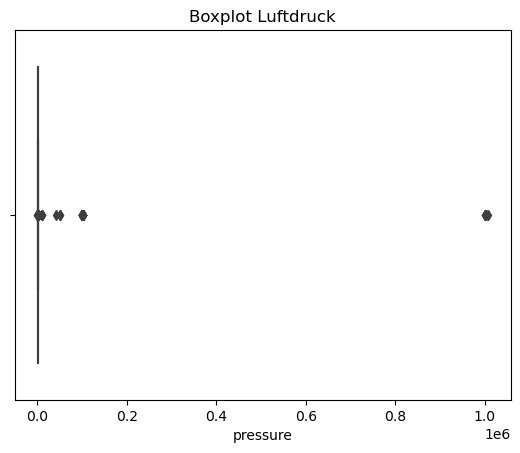

In [17]:
sns.boxplot(x='pressure', data=weather_df)
plt.title("Boxplot Luftdruck")
plt.show()

Zur genaueren Analyse wurde aus den Werten in der Spalte *pressure* ein Boxplot erstellt, wobei zu erkennen ist, dass es zwei Ausreißer nach oben gibt. Diese Ausreißer werden nun durch "NaN-Werte" ersetzt.

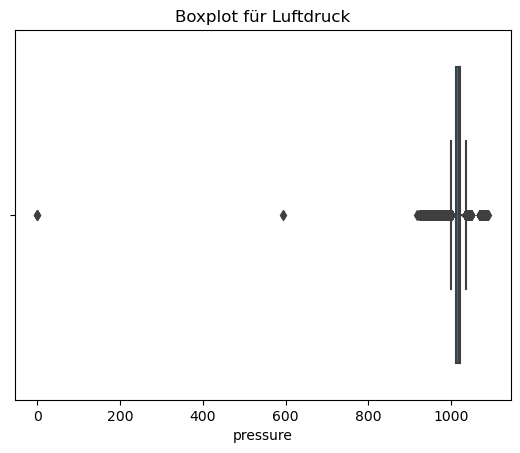

In [18]:
if weather_df.index.duplicated().any():
    weather_df.reset_index(drop=True, inplace=True)
weather_df.loc[weather_df['pressure'] > 1100, 'pressure'] = np.nan
sns.boxplot(x='pressure', data=weather_df)
plt.title("Boxplot für Luftdruck")
plt.show()

Die Abbildung zeigt ebenfalls zwei Ausreißer nach unten. Da der niedrigste auf der Erde gemessene Luftdruck bei 865 hPa liegt, werden alle Werte unter 865 hPa durch "NaN-Werte" ersetzt [7].

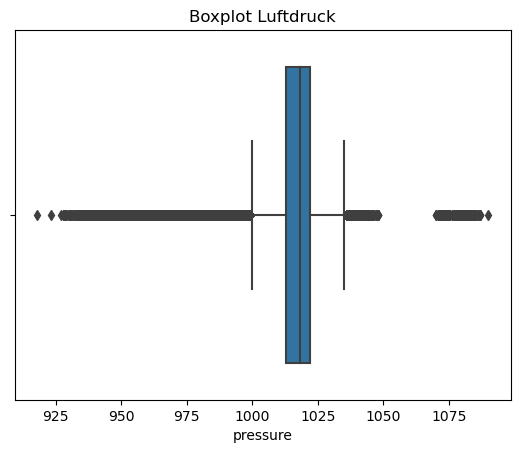

In [19]:
weather_df.loc[weather_df['pressure'] < 865, 'pressure'] = np.nan
sns.boxplot(x='pressure', data=weather_df)
plt.title("Boxplot Luftdruck")
plt.show()

Auffällig an der Verteilung sind die Datenpunkte zwischen den Werten 1060 und 2000 hPa und die damit verbundene "Zweiteilung". Um diese genauer analysieren zu können, wird ein Histogramm erstellt. 

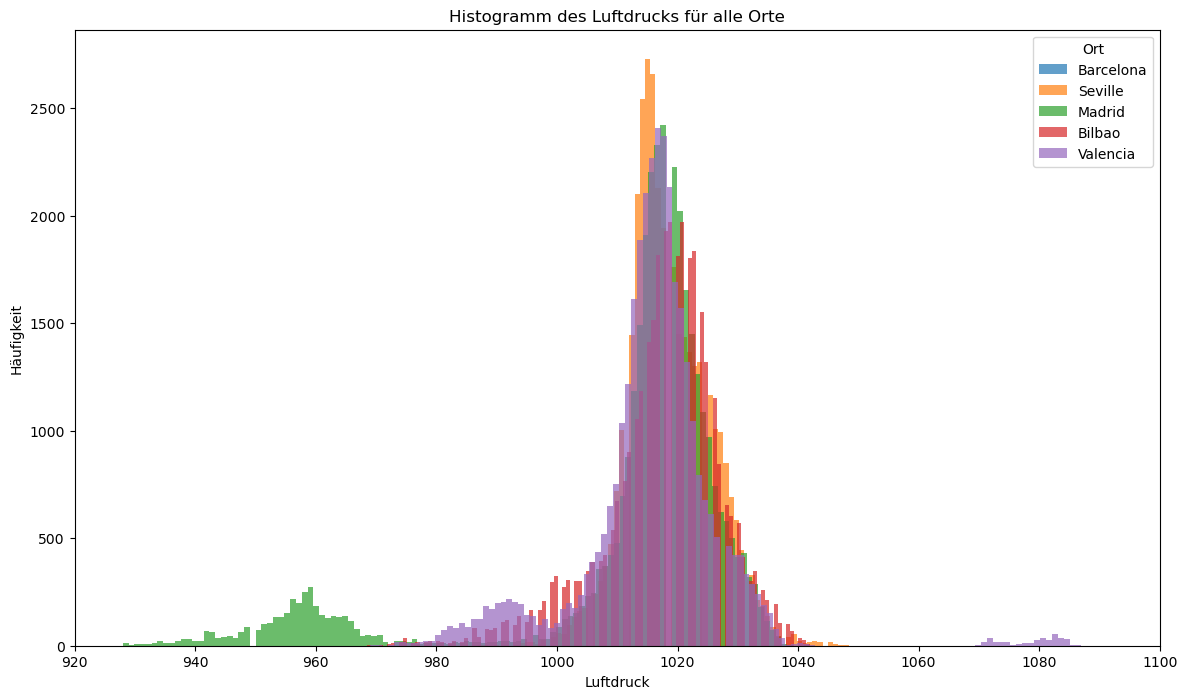

In [20]:
barcelona_data = weather_df[weather_df['city_name'] == 'Barcelona']['pressure']
seville_data = weather_df[weather_df['city_name'] == 'Seville']['pressure']
madrid_data = weather_df[weather_df['city_name'] == 'Madrid']['pressure']
bilbao_data = weather_df[weather_df['city_name'] == 'Bilbao']['pressure']
valencia_data = weather_df[weather_df['city_name'] == 'Valencia']['pressure']
all_data = pd.concat([barcelona_data, seville_data, madrid_data, bilbao_data, valencia_data], axis=1)
all_data.columns = ['Barcelona', 'Seville', 'Madrid', 'Bilbao', 'Valencia']
plt.figure(figsize=(14, 8))
for city_name in all_data.columns:
    city_data = all_data[city_name].dropna()
    plt.hist(city_data, bins=120, alpha=0.7, label=city_name)
plt.title('Histogramm des Luftdrucks für alle Orte')
plt.xlabel('Luftdruck')
plt.ylabel('Häufigkeit')
plt.legend(title='Ort')
plt.xlim(left=920, right=1100)
plt.show()

Anhand des Histogramms ist zu erkennen, dass die auffälligen Datenpunkte ausnahmslos in Valencia liegen. Da der in den Jahren 1940 bis 2023 maximale jemals gemessene Luftdruck bei 1015 hPa liegt, werden alle Datenpunkte überhalb des Werts 1060 ebenfalls aus dem Datensatz entfernt und durch "NaN-Werte" ersetzt [8].

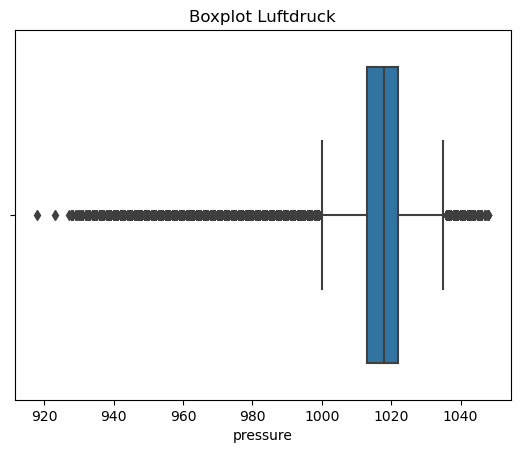

In [21]:
weather_df.loc[weather_df['pressure'] > 1060, 'pressure'] = np.nan
sns.boxplot(x='pressure', data=weather_df)
plt.title("Boxplot Luftdruck")
plt.show()

Die Daten wurden entsprechend angepasst, indem alle Werte über 1060 hPa aus dem Datensatz entfernt und durch "NaN-Werte" ersetzt wurden.

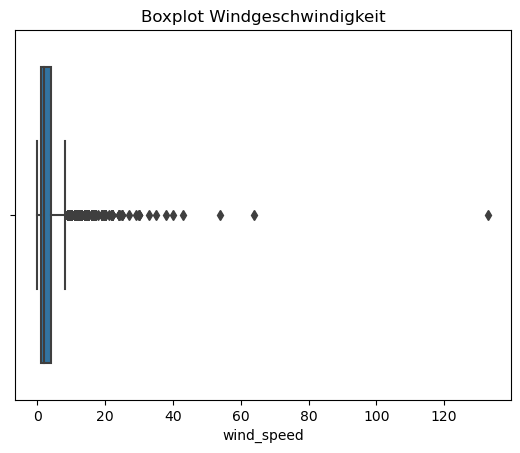

In [22]:
sns.boxplot(x='wind_speed', data=weather_df)
plt.title('Boxplot Windgeschwindigkeit')
plt.show()

Aus der Abbildung ist zu entnehmen, dass ein bzw. drei Ausreißer nach oben existieren. Diese werden ebenfalls durch "NaN-Werte" ersetzt.

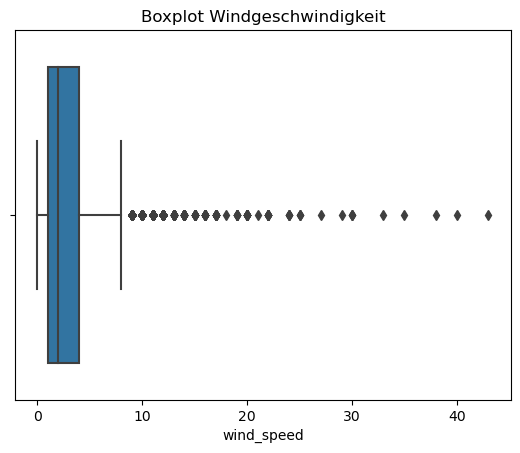

In [23]:
weather_df.loc[weather_df['wind_speed'] > 50, 'wind_speed'] = np.nan
sns.boxplot(x='wind_speed', data=weather_df)
plt.title("Boxplot Windgeschwindigkeit")
plt.show()

Anhand des Boxplots ist zu erkennen, dass die Daten nun keine Ausreißer nach oben oder unten mehr aufweisen und die Datenaufbereitung erfolgreich war.

In [24]:
weather_main = weather_df['weather_main'].unique()
weather_main

array(['clear', 'clouds', 'rain', 'mist', 'thunderstorm', 'drizzle',
       'fog', 'smoke', 'haze', 'snow', 'dust', 'squall'], dtype=object)

In [25]:
weather_id = weather_df['weather_id'].unique()
weather_id

array([800., 801., 802., 803., 804., 500., 501., 502., 701., 522., 521.,
       503., 202., 200., 211., 520., 300., 201., 741., 711., 301., 302.,
       721., 600., 616., 615., 601., 611., 311., 310., 620., 531., 602.,
       731., 761., 210., 771.])

In [26]:
weather_description = weather_df['weather_description'].unique()
weather_description

array(['sky is clear', 'few clouds', 'scattered clouds', 'broken clouds',
       'overcast clouds', 'light rain', 'moderate rain',
       'heavy intensity rain', 'mist', 'heavy intensity shower rain',
       'shower rain', 'very heavy rain', 'thunderstorm with heavy rain',
       'thunderstorm with light rain', 'proximity thunderstorm',
       'thunderstorm', 'light intensity shower rain',
       'light intensity drizzle', 'thunderstorm with rain', 'fog',
       'smoke', 'drizzle', 'heavy intensity drizzle', 'haze',
       'proximity shower rain', 'light snow', 'rain and snow',
       'light rain and snow', 'snow', 'sleet', 'rain and drizzle',
       'light intensity drizzle rain', 'light shower snow',
       'proximity moderate rain', 'ragged shower rain', 'heavy snow',
       'sand dust whirls', 'proximity drizzle', 'dust',
       'light thunderstorm', 'squalls'], dtype=object)

Es werden anschließend noch die in den Spalten *weather_main*, *weather_id* und *weather_description* vorkommenden Werte zur Beschreibung des Wetters ausgegeben. Daraus lässt sich schließen, dass die in den Spalten *weather_id* und *weather_description* vorkommenden Angaben mit einer Anzahl von 38 bzw. 43 Werten am detailreichsten sind. Es werden entfernen die Spalten *weather_description* und *weather_id* aus dem Datensatz entfernt und die Spalte *weather_main* weitergenutzt, um den Datensatz nicht zu "überfrachten", da die qualitativ vorliegenden Daten noch "One-Hot_Encoded" werden müssen. Dieser Prozess wird im späteren Verlauf näher erläutert.
Die Spalte *weather_icon* wird ebenfalls aus dem Datensatz entfernt, da sie keine, für den weiteren Verlauf, relevanten Daten beinhaltet.

In [27]:
weather_df = weather_df.drop(['weather_description', 'weather_id', 'weather_icon'], axis=1)
weather_df.head()

,time,city_name,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_main
0,2014-12-31 23:00:00+00:00,Valencia,270.475,270.475,270.475,1001.0,77.0,1.0,62.0,0.0,0.0,0.0,0.0,clear
1,2015-01-01 00:00:00+00:00,Valencia,270.475,270.475,270.475,1001.0,77.0,1.0,62.0,0.0,0.0,0.0,0.0,clear
2,2015-01-01 01:00:00+00:00,Valencia,269.686,269.686,269.686,1002.0,78.0,0.0,23.0,0.0,0.0,0.0,0.0,clear
3,2015-01-01 02:00:00+00:00,Valencia,269.686,269.686,269.686,1002.0,78.0,0.0,23.0,0.0,0.0,0.0,0.0,clear
4,2015-01-01 03:00:00+00:00,Valencia,269.686,269.686,269.686,1002.0,78.0,0.0,23.0,0.0,0.0,0.0,0.0,clear


Aus den ersten Zeilen des Datensatzes ist zu erkennen, dass der Datensatz erfolgreich geändert wurde, indem die Spalten *weather_main*, *weather_id* und *weather_description* aus dem Datensatz entfernt wurden. 

In [28]:
fehlende_werte_weather = weather_df.isnull().sum(axis=0)
fehlende_werte_tabelle = pd.DataFrame({'Name der jeweiligen Spalte': fehlende_werte_weather.index, 'Anzahl der "NaN-Werte"': fehlende_werte_weather.values})
fehlende_werte_tabelle

,Name der jeweiligen Spalte,"Anzahl der ""NaN-Werte"""
0,time,0
1,city_name,0
2,temp,0
3,temp_min,0
4,temp_max,0
5,pressure,415
6,humidity,0
7,wind_speed,3
8,wind_deg,0
9,rain_1h,0


Nun sollen noch alle NaN-Werte mithilfe der AutoRegressive Integrated Moving Average-Methode (ARIMA) approximiert werden. Diese Methode oft verwendet, um fehlende Werte in Zeitreihen zu approximieren. Sie besteht aus mehreren Hautpkomponenten: Autoregression (AR), Integration (I) und Moving Average (MA). Innerhalb der Komponente Autoregression wird die Beziehung zwischen aktuellen und vergangenen Werten einer Zeitreihe genutzt, um Muster zu erkennen. In der Komponente Integration werden nicht-stationäre Zeitreihen in stationäre umgewandelt, bei denen Mittelwert und Varianz konstant bleiben, um eine effektivere Arbeitsweise der Methode zu gewährleisten. Schließlich wird innerhalb der Komponente Moving Average die Vorhersage durch die Analyse der Fehler vorheriger Prognosen verbessert, um Anpassungen für zukünftige Vorhersagen zu treffen [4].

In [29]:
def calculate_max_consecutive_nans(series):
    return series.isna().astype(int).groupby(series.notna().astype(int).cumsum()).sum().max()
def calculate_consecutive_nans_greater_than(df, threshold=5):
    results = []
    for column in df.columns:
        if df[column].dtype in ['float64', 'int64']:
            max_nans = calculate_max_consecutive_nans(df[column])
            if max_nans > threshold:
                results.append({'column': column, 'max_consecutive_nans': max_nans})
    return results
numeric_columns = ['temp', 'temp_min', 'temp_max', 'pressure', 'humidity', 'wind_speed', 'wind_deg', 'rain_1h', 'rain_3h', 'snow_3h', 'clouds_all']
numeric_df = weather_df[numeric_columns]
results = calculate_consecutive_nans_greater_than(numeric_df, threshold=5)
results_df = pd.DataFrame(results)
print('Spalten mit Lücken größer als fünf aufeinanderfolgender "NaN-Werte" und deren maximale Größe:')
print(results_df)

Spalten mit Lücken größer als fünf aufeinanderfolgender "NaN-Werte" und deren maximale Größe:
     column  max_consecutive_nans
0  pressure                   140


Der Datensatz verfügt über nur eine Spalte, innerhalb derer zwischen fünf und 140 aufeinanderfolgende Daten fehlen. Aufgrund der Größe des Datensatzes ist diese "Lücke" noch klein genug, um die Werte mithilfe der ARIMA-Methode zu approximieren. 

In [30]:
def impute_with_arima(series, order=(1,1,1)):
    import warnings
    warnings.filterwarnings("ignore")
    approximated_indices = [] 
    if series.isna().any():
        try:
            series_interpolated = series.interpolate()
            model = ARIMA(series_interpolated, order=order)
            model_fit = model.fit()
            predictions = model_fit.predict(start=0, end=len(series) - 1)
            series_filled = series.copy()
            nan_indices = series[series.isna()].index
            series_filled.loc[nan_indices] = predictions.loc[nan_indices]
            approximated_indices.extend(nan_indices.tolist()) 
            return series_filled, approximated_indices
        except Exception as e:
            print(f"ARIMA-Anwendung fehlgeschlagen: {e}")
            return series, approximated_indices
    else:
        return series, approximated_indices
nan_count_before = weather_df.isna().sum().sum()
print(f"Anzahl der NaN-Werte vor der Imputation: {nan_count_before}")
approximated_indices_per_column = {}  
for column in ['temp', 'temp_min', 'temp_max', 'pressure', 'humidity', 'wind_speed', 'wind_deg', 'rain_1h', 'rain_3h', 'snow_3h', 'clouds_all']:
    if column in weather_df.columns:
        weather_df[column], approximated_indices = impute_with_arima(weather_df[column])
        if approximated_indices:
            approximated_indices_per_column[column] = approximated_indices
nan_count_after = weather_df.isna().sum().sum()
print(f"Anzahl der NaN-Werte nach der Imputation: {nan_count_after}")

Anzahl der NaN-Werte vor der Imputation: 418
Anzahl der NaN-Werte nach der Imputation: 0


Die "NaN-Werte" wurden erfolgreich mithilfe der ARIMA-Methode approximiert.

### 2.3.2 Dataframe *energy*

In [31]:
fehlende_werte_energy = energy_df.isnull().sum(axis=0)
fehlende_werte_tabelle = pd.DataFrame({'Name der jeweiligen Spalte': fehlende_werte_energy.index, 'Anzahl der "NaN-Werte"': fehlende_werte_energy.values})
fehlende_werte_tabelle

,Name der jeweiligen Spalte,"Anzahl der ""NaN-Werte"""
0,time,0
1,generation biomass,19
2,generation fossil brown coal/lignite,18
3,generation fossil gas,18
4,generation fossil hard coal,18
5,generation fossil oil,19
6,generation hydro pumped storage consumption,19
7,generation hydro run-of-river and poundage,19
8,generation hydro water reservoir,18
9,generation nuclear,17


Die Tabelle zeigt die Anzahl der "NaN-Werte", die in den einzelnen Spalten vorhanden sind. Da es sich hierbei um eine Zeitreihenanalyse handelt, ist es nötig, die einzelnen fehlenden Werte zu interpolieren, um die Anzahl der Daten zu maximieren und damit wiederum eine möglichst genaue Vorhersage treffen zu können. Es ist zu erkennen, dass die meisten "NaN-Werte" in der Spalte *total load actual* vorkommen und sich alle anderen Null-Werte hinsichtlich ihres Auftretens zwischen den Werten 17 und 19 bewegen. 

In [32]:
selected_columns_energy = ['generation biomass', 'generation fossil brown coal/lignite', 'generation fossil gas', 'generation fossil hard coal', 'generation fossil oil', 'generation hydro pumped storage consumption', 'generation hydro run-of-river and poundage', 'generation hydro water reservoir', 'generation nuclear', 'generation other', 'generation other renewable', 'generation solar', 'generation waste', 'generation wind onshore', 'total load actual', 'price day ahead', 'price actual']
numeric_df = energy_df[selected_columns_energy]
nan_gap_results = calculate_consecutive_nans_greater_than(numeric_df, 5)
nan_gap_results_df = pd.DataFrame(nan_gap_results)
print("Spalten mit Lücken größer als fünf aufeinanderfolgender 'NaN-Werte' und deren maximale Größe:")
print(nan_gap_results_df)

Spalten mit Lücken größer als fünf aufeinanderfolgender 'NaN-Werte' und deren maximale Größe:
                                         column  max_consecutive_nans
0                            generation biomass                     6
1          generation fossil brown coal/lignite                     6
2                         generation fossil gas                     6
3                   generation fossil hard coal                     6
4                         generation fossil oil                     6
5   generation hydro pumped storage consumption                     6
6    generation hydro run-of-river and poundage                     6
7              generation hydro water reservoir                     6
8                            generation nuclear                     6
9                              generation other                     6
10                   generation other renewable                     6
11                             generation solar                   

Es wird ebenfalls die ARIMA-Methode verwendet, um die fehlenden Werte zu approximieren.

In [33]:
selected_columns_energy = ['generation biomass', 'generation fossil brown coal/lignite', 'generation fossil gas', 'generation fossil hard coal', 'generation fossil oil', 'generation hydro pumped storage consumption', 'generation hydro run-of-river and poundage', 'generation hydro water reservoir', 'generation nuclear', 'generation other', 'generation other renewable', 'generation solar', 'generation waste', 'generation wind onshore', 'total load actual', 'price day ahead', 'price actual'] 
nan_count_before = energy_df[selected_columns_energy].isna().sum().sum()
print(f"Anzahl der NaN-Werte vor der Imputation im energy_df: {nan_count_before}")
for column in selected_columns_energy:
    if column in energy_df.columns:
        energy_df[column], _ = impute_with_arima(energy_df[column], order=(1, 1, 1))
nan_count_after = energy_df[selected_columns_energy].isna().sum().sum()
print(f"Anzahl der NaN-Werte nach der Imputation im energy_df: {nan_count_after}")

Anzahl der NaN-Werte vor der Imputation im energy_df: 292
Anzahl der NaN-Werte nach der Imputation im energy_df: 0


Die "NaN-Werte" wurden erfolgreich mithilfe der ARIMA-Methode approximiert.

In [34]:
print('"Nicht-Null-Werte" in Spalte:\n', energy_df.astype(bool).sum(axis=0), sep='\n')

"Nicht-Null-Werte" in Spalte:

time                                           35064
generation biomass                             35060
generation fossil brown coal/lignite           24547
generation fossil gas                          35063
generation fossil hard coal                    35061
generation fossil oil                          35061
generation hydro pumped storage consumption    22457
generation hydro run-of-river and poundage     35061
generation hydro water reservoir               35061
generation nuclear                             35061
generation other                               35060
generation other renewable                     35061
generation solar                               35061
generation waste                               35061
generation wind onshore                        35061
total load actual                              35064
price day ahead                                35064
price actual                                   35064
dtype: int64


Die Spalten *generation fossil brown coal/lignite* und *generation hydro pumped storage consumption* verfügen noch über auffallend viele Null-Werte. Dies kann zumindest in der Spalte *generation hydro pumped storage consumption* dadurch erklärt werden, dass diese Art von Kraftwerk nur zum Abfangen Spitzenlasten eingesetzt wird. 

### 2.3.3 Zusammenführung der Datensätze

Die beiden Datensätze *weather* und *energy* sollen innerhalb dieses Abschnitts zusammengeführt werden, um mithilfe dieses neu entstehenden Datensatzes anschließend weiterarbeiten zu können.

In [35]:
weather_df['city_name'] = weather_df['city_name'].str.strip()
weather_one_hot = pd.get_dummies(weather_df, columns=['city_name'])
new_columns = {}
for col in weather_one_hot.columns:
    if col.startswith('city_name_'):
        city = col.split('city_name_')[1]
        for w_col in ['temp', 'temp_min', 'temp_max', 'pressure', 'humidity', 'wind_speed', 'wind_deg', 'rain_1h', 'rain_3h', 'snow_3h', 'clouds_all', 'weather_main']:
            if w_col in weather_one_hot.columns:
                new_columns[f"{w_col}_{city}"] = weather_one_hot[w_col] * weather_one_hot[col]
            else:
                new_columns[f"{w_col}_{city}"] = 0
weather_one_hot = weather_one_hot.assign(**new_columns)
columns_to_drop = ['temp', 'temp_min', 'temp_max', 'pressure', 'humidity', 'wind_speed', 'wind_deg', 'rain_1h', 'rain_3h', 'snow_3h', 'clouds_all', 'weather_main'] + [col for col in weather_one_hot.columns if col.startswith('city_name_')]
weather_one_hot.drop(columns=columns_to_drop, inplace=True)
combined_df = pd.merge(energy_df, weather_one_hot, on='time', how='left')
combined_df.head(10)

,time,generation biomass,generation fossil brown coal/lignite,generation fossil gas,generation fossil hard coal,generation fossil oil,generation hydro pumped storage consumption,generation hydro run-of-river and poundage,generation hydro water reservoir,generation nuclear,...,temp_max_Valencia,pressure_Valencia,humidity_Valencia,wind_speed_Valencia,wind_deg_Valencia,rain_1h_Valencia,rain_3h_Valencia,snow_3h_Valencia,clouds_all_Valencia,weather_main_Valencia
0,2014-12-31 23:00:00+00:00,447.0,329.0,4844.0,4821.0,162.0,863.0,1051.0,1899.0,7096.0,...,270.475,1001.0,77.0,1.0,62.0,0.0,0.0,0.0,0.0,clear
1,2014-12-31 23:00:00+00:00,447.0,329.0,4844.0,4821.0,162.0,863.0,1051.0,1899.0,7096.0,...,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,
2,2014-12-31 23:00:00+00:00,447.0,329.0,4844.0,4821.0,162.0,863.0,1051.0,1899.0,7096.0,...,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,
3,2014-12-31 23:00:00+00:00,447.0,329.0,4844.0,4821.0,162.0,863.0,1051.0,1899.0,7096.0,...,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,
4,2014-12-31 23:00:00+00:00,447.0,329.0,4844.0,4821.0,162.0,863.0,1051.0,1899.0,7096.0,...,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,
5,2015-01-01 00:00:00+00:00,449.0,328.0,5196.0,4755.0,158.0,920.0,1009.0,1658.0,7096.0,...,270.475,1001.0,77.0,1.0,62.0,0.0,0.0,0.0,0.0,clear
6,2015-01-01 00:00:00+00:00,449.0,328.0,5196.0,4755.0,158.0,920.0,1009.0,1658.0,7096.0,...,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,
7,2015-01-01 00:00:00+00:00,449.0,328.0,5196.0,4755.0,158.0,920.0,1009.0,1658.0,7096.0,...,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,
8,2015-01-01 00:00:00+00:00,449.0,328.0,5196.0,4755.0,158.0,920.0,1009.0,1658.0,7096.0,...,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,
9,2015-01-01 00:00:00+00:00,449.0,328.0,5196.0,4755.0,158.0,920.0,1009.0,1658.0,7096.0,...,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,


Die Daten wurden anhand der Zeit in die Variable combined_df zusammengeführt.

# 3. Datenvisualisierung

In [36]:
weather_main_columns = [col for col in combined_df.columns if col.startswith('weather_main_')]
df_encoded = pd.get_dummies(combined_df, columns=weather_main_columns)
pd.set_option('display.max_columns', None)
df_encoded.drop(columns=['weather_main_Valencia_', 'weather_main_Barcelona_', 'weather_main_Seville_', 'weather_main_Madrid_', 'weather_main_Bilbao_'], inplace=True)
combined_df = df_encoded
combined_df.columns = combined_df.columns.str.replace(' ', '_').str.strip()
combined_df.head()

,time,generation_biomass,generation_fossil_brown_coal/lignite,generation_fossil_gas,generation_fossil_hard_coal,generation_fossil_oil,generation_hydro_pumped_storage_consumption,generation_hydro_run-of-river_and_poundage,generation_hydro_water_reservoir,generation_nuclear,generation_other,generation_other_renewable,generation_solar,generation_waste,generation_wind_onshore,total_load_actual,price_day_ahead,price_actual,temp_Barcelona,temp_min_Barcelona,temp_max_Barcelona,pressure_Barcelona,humidity_Barcelona,wind_speed_Barcelona,wind_deg_Barcelona,rain_1h_Barcelona,rain_3h_Barcelona,snow_3h_Barcelona,clouds_all_Barcelona,temp_Bilbao,temp_min_Bilbao,temp_max_Bilbao,pressure_Bilbao,humidity_Bilbao,wind_speed_Bilbao,wind_deg_Bilbao,rain_1h_Bilbao,rain_3h_Bilbao,snow_3h_Bilbao,clouds_all_Bilbao,temp_Madrid,temp_min_Madrid,temp_max_Madrid,pressure_Madrid,humidity_Madrid,wind_speed_Madrid,wind_deg_Madrid,rain_1h_Madrid,rain_3h_Madrid,snow_3h_Madrid,clouds_all_Madrid,temp_Seville,temp_min_Seville,temp_max_Seville,pressure_Seville,humidity_Seville,wind_speed_Seville,wind_deg_Seville,rain_1h_Seville,rain_3h_Seville,snow_3h_Seville,clouds_all_Seville,temp_Valencia,temp_min_Valencia,temp_max_Valencia,pressure_Valencia,humidity_Valencia,wind_speed_Valencia,wind_deg_Valencia,rain_1h_Valencia,rain_3h_Valencia,snow_3h_Valencia,clouds_all_Valencia,weather_main_Barcelona_clear,weather_main_Barcelona_clouds,weather_main_Barcelona_drizzle,weather_main_Barcelona_dust,weather_main_Barcelona_fog,weather_main_Barcelona_mist,weather_main_Barcelona_rain,weather_main_Barcelona_snow,weather_main_Barcelona_thunderstorm,weather_main_Bilbao_clear,weather_main_Bilbao_clouds,weather_main_Bilbao_drizzle,weather_main_Bilbao_fog,weather_main_Bilbao_haze,weather_main_Bilbao_mist,weather_main_Bilbao_rain,weather_main_Bilbao_snow,weather_main_Bilbao_thunderstorm,weather_main_Madrid_clear,weather_main_Madrid_clouds,weather_main_Madrid_drizzle,weather_main_Madrid_fog,weather_main_Madrid_haze,weather_main_Madrid_mist,weather_main_Madrid_rain,weather_main_Madrid_snow,weather_main_Madrid_thunderstorm,weather_main_Seville_clear,weather_main_Seville_clouds,weather_main_Seville_drizzle,weather_main_Seville_dust,weather_main_Seville_fog,weather_main_Seville_haze,weather_main_Seville_mist,weather_main_Seville_rain,weather_main_Seville_smoke,weather_main_Seville_squall,weather_main_Seville_thunderstorm,weather_main_Valencia_clear,weather_main_Valencia_clouds,weather_main_Valencia_drizzle,weather_main_Valencia_fog,weather_main_Valencia_haze,weather_main_Valencia_mist,weather_main_Valencia_rain,weather_main_Valencia_smoke,weather_main_Valencia_thunderstorm
0,2014-12-31 23:00:00+00:00,447.0,329.0,4844.0,4821.0,162.0,863.0,1051.0,1899.0,7096.0,43.0,73.0,49.0,196.0,6378.0,25385.0,50.1,65.41,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,270.475,270.475,270.475,1001.0,77.0,1.0,62.0,0.0,0.0,0.0,0.0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False
1,2014-12-31 23:00:00+00:00,447.0,329.0,4844.0,4821.0,162.0,863.0,1051.0,1899.0,7096.0,43.0,73.0,49.0,196.0,6378.0,25385.0,50.1,65.41,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,267.325,267.325,267.325,971.0,63.0,1.0,309.0,0.0,0.0,0.0,0.0,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,F

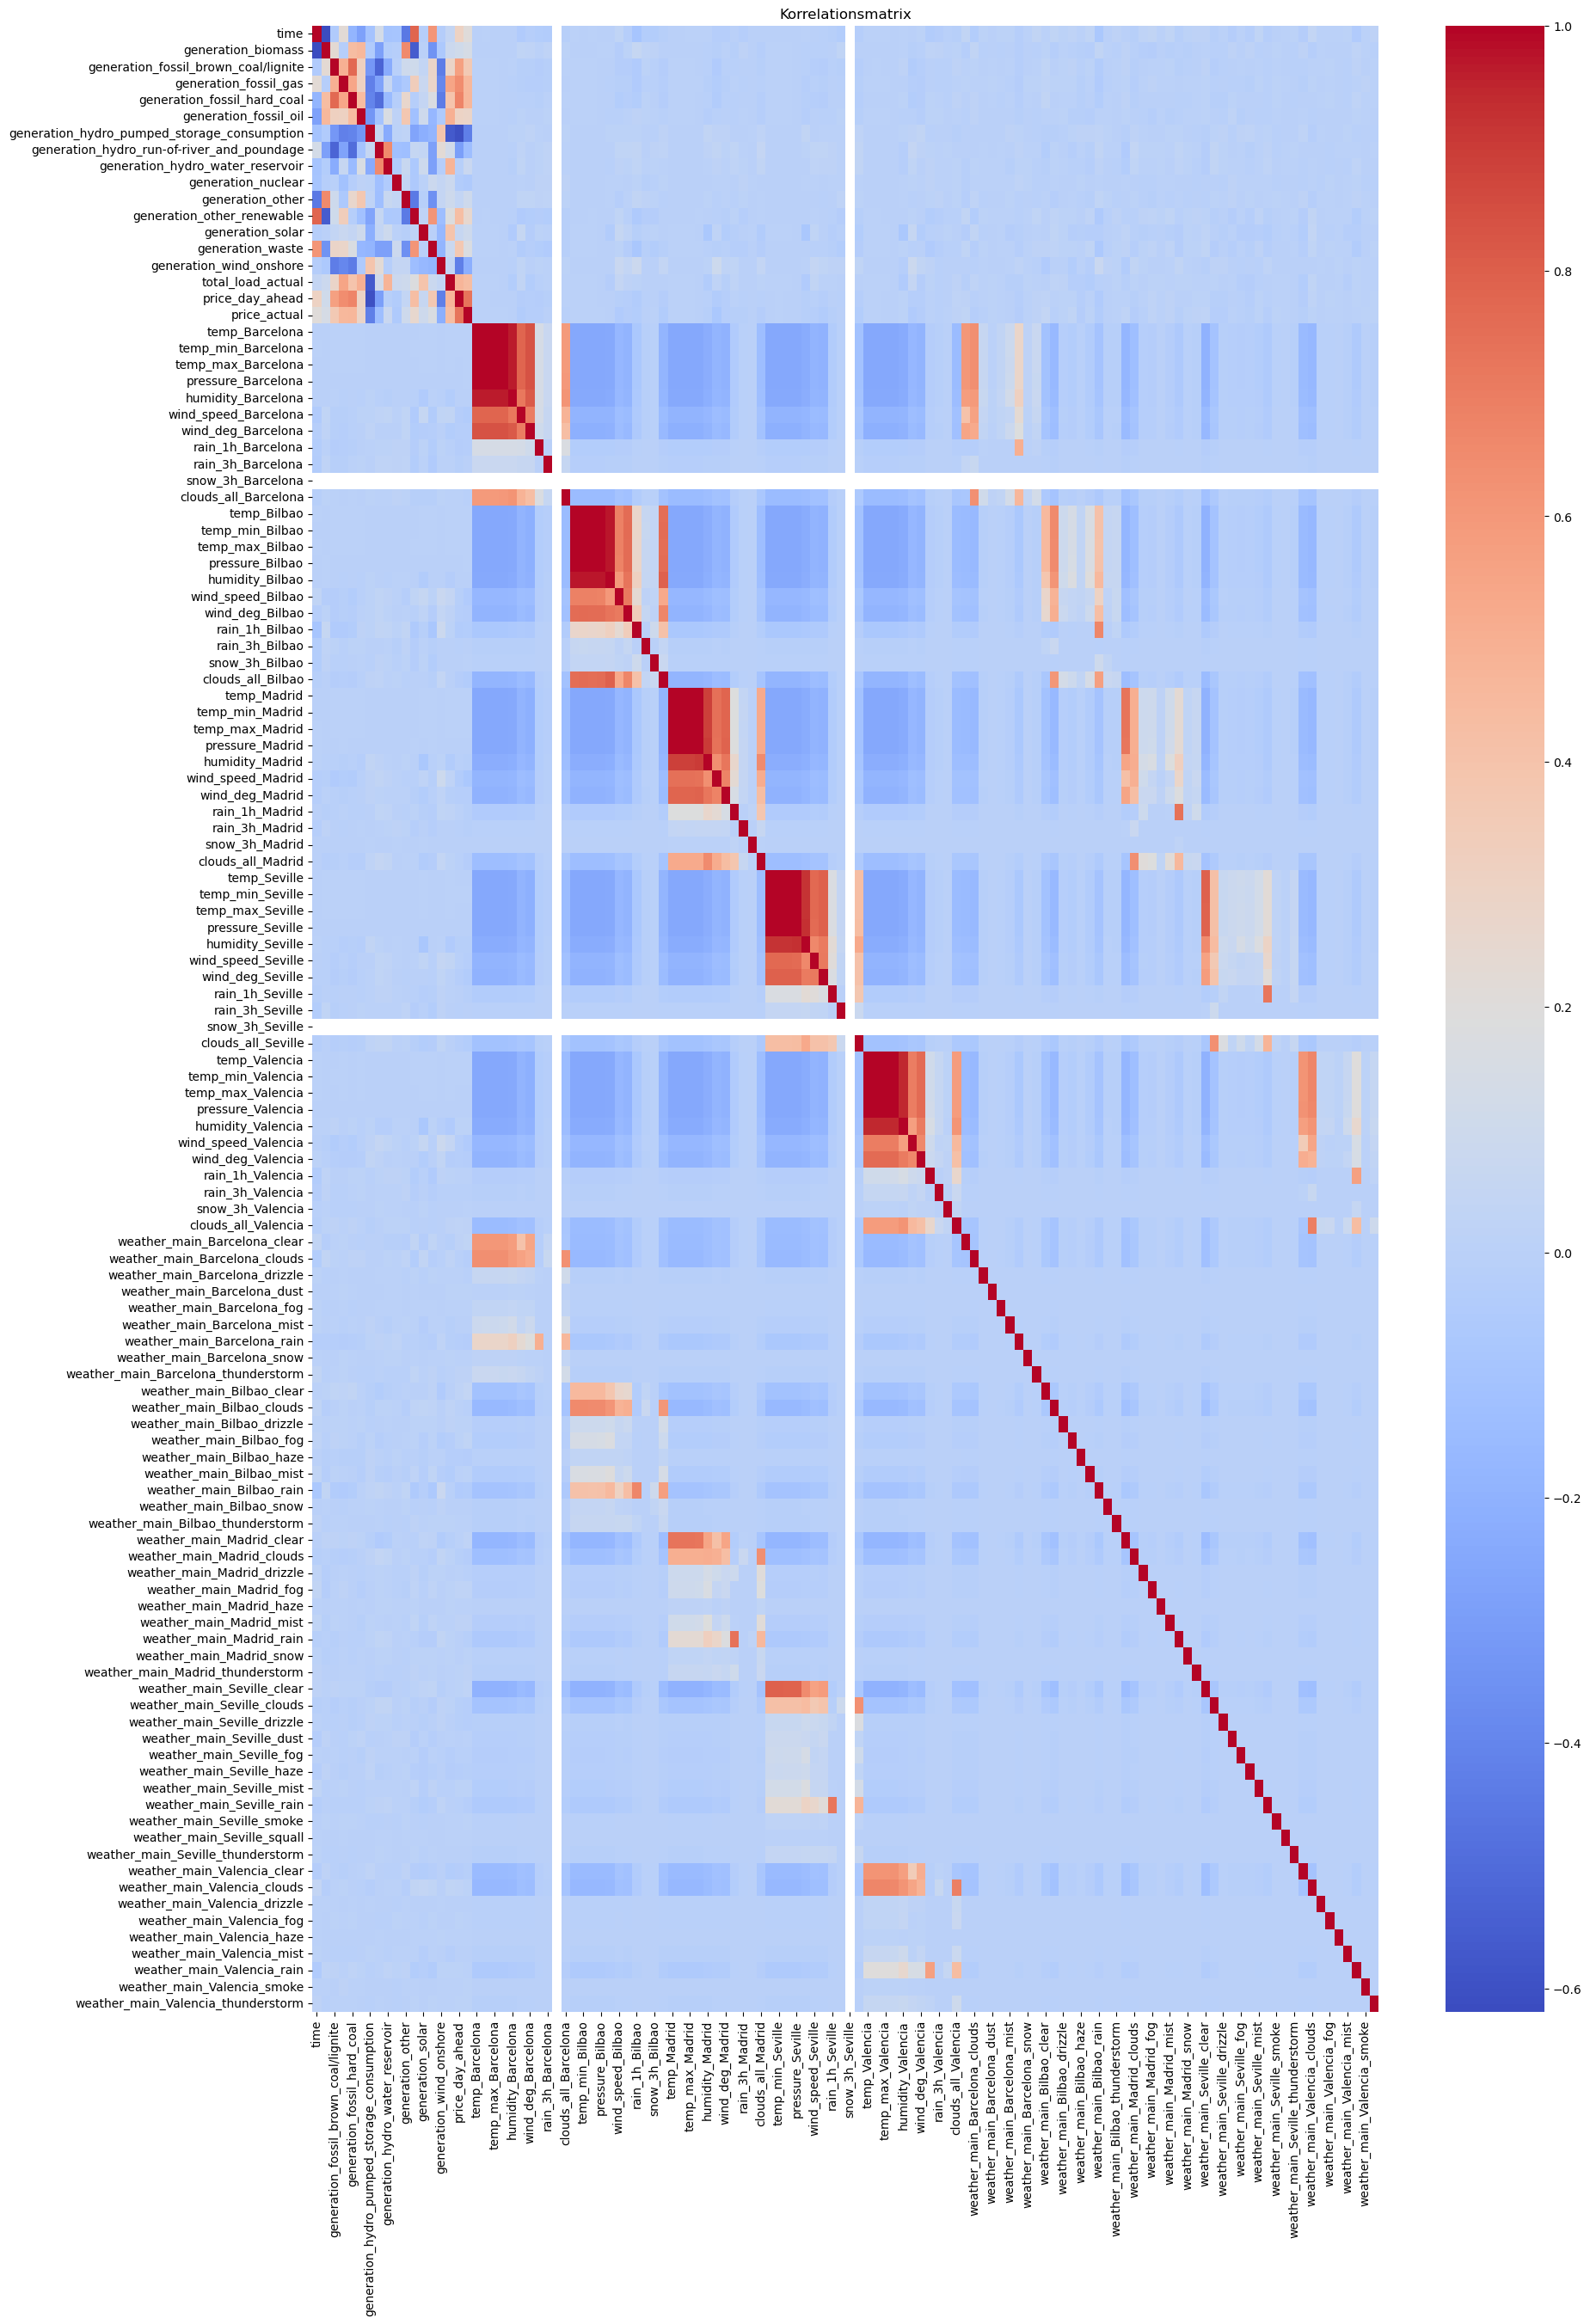

In [37]:
corr_matrix = combined_df.corr()
plt.figure(figsize=(20, 30))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', fmt=".2f")
plt.title('Korrelationsmatrix')
plt.show()

Aus der Korrelationsmatrix ist unter anderem zu erkennen, dass zwischen den Variablen *snow_3h_Barcelona* sowie *snow_3h_Seville* und allen weiteren Daten keine Korrelation besteht, weswegen diese Spalten aus dem Datensatz entfernt werden.

In [38]:
combined_df.drop(columns=['snow_3h_Seville', 'snow_3h_Barcelona'], inplace=True)
combined_df.head()

,time,generation_biomass,generation_fossil_brown_coal/lignite,generation_fossil_gas,generation_fossil_hard_coal,generation_fossil_oil,generation_hydro_pumped_storage_consumption,generation_hydro_run-of-river_and_poundage,generation_hydro_water_reservoir,generation_nuclear,generation_other,generation_other_renewable,generation_solar,generation_waste,generation_wind_onshore,total_load_actual,price_day_ahead,price_actual,temp_Barcelona,temp_min_Barcelona,temp_max_Barcelona,pressure_Barcelona,humidity_Barcelona,wind_speed_Barcelona,wind_deg_Barcelona,rain_1h_Barcelona,rain_3h_Barcelona,clouds_all_Barcelona,temp_Bilbao,temp_min_Bilbao,temp_max_Bilbao,pressure_Bilbao,humidity_Bilbao,wind_speed_Bilbao,wind_deg_Bilbao,rain_1h_Bilbao,rain_3h_Bilbao,snow_3h_Bilbao,clouds_all_Bilbao,temp_Madrid,temp_min_Madrid,temp_max_Madrid,pressure_Madrid,humidity_Madrid,wind_speed_Madrid,wind_deg_Madrid,rain_1h_Madrid,rain_3h_Madrid,snow_3h_Madrid,clouds_all_Madrid,temp_Seville,temp_min_Seville,temp_max_Seville,pressure_Seville,humidity_Seville,wind_speed_Seville,wind_deg_Seville,rain_1h_Seville,rain_3h_Seville,clouds_all_Seville,temp_Valencia,temp_min_Valencia,temp_max_Valencia,pressure_Valencia,humidity_Valencia,wind_speed_Valencia,wind_deg_Valencia,rain_1h_Valencia,rain_3h_Valencia,snow_3h_Valencia,clouds_all_Valencia,weather_main_Barcelona_clear,weather_main_Barcelona_clouds,weather_main_Barcelona_drizzle,weather_main_Barcelona_dust,weather_main_Barcelona_fog,weather_main_Barcelona_mist,weather_main_Barcelona_rain,weather_main_Barcelona_snow,weather_main_Barcelona_thunderstorm,weather_main_Bilbao_clear,weather_main_Bilbao_clouds,weather_main_Bilbao_drizzle,weather_main_Bilbao_fog,weather_main_Bilbao_haze,weather_main_Bilbao_mist,weather_main_Bilbao_rain,weather_main_Bilbao_snow,weather_main_Bilbao_thunderstorm,weather_main_Madrid_clear,weather_main_Madrid_clouds,weather_main_Madrid_drizzle,weather_main_Madrid_fog,weather_main_Madrid_haze,weather_main_Madrid_mist,weather_main_Madrid_rain,weather_main_Madrid_snow,weather_main_Madrid_thunderstorm,weather_main_Seville_clear,weather_main_Seville_clouds,weather_main_Seville_drizzle,weather_main_Seville_dust,weather_main_Seville_fog,weather_main_Seville_haze,weather_main_Seville_mist,weather_main_Seville_rain,weather_main_Seville_smoke,weather_main_Seville_squall,weather_main_Seville_thunderstorm,weather_main_Valencia_clear,weather_main_Valencia_clouds,weather_main_Valencia_drizzle,weather_main_Valencia_fog,weather_main_Valencia_haze,weather_main_Valencia_mist,weather_main_Valencia_rain,weather_main_Valencia_smoke,weather_main_Valencia_thunderstorm
0,2014-12-31 23:00:00+00:00,447.0,329.0,4844.0,4821.0,162.0,863.0,1051.0,1899.0,7096.0,43.0,73.0,49.0,196.0,6378.0,25385.0,50.1,65.41,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,270.475,270.475,270.475,1001.0,77.0,1.0,62.0,0.0,0.0,0.0,0.0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False
1,2014-12-31 23:00:00+00:00,447.0,329.0,4844.0,4821.0,162.0,863.0,1051.0,1899.0,7096.0,43.0,73.0,49.0,196.0,6378.0,25385.0,50.1,65.41,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,267.325,267.325,267.325,971.0,63.0,1.0,309.0,0.0,0.0,0.0,0.0,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,2014-12-31 23:00:00+00:00

In [39]:
correlation_series = corr_matrix.stack()
correlation_df = pd.DataFrame(correlation_series, columns=['Korrelation']).reset_index()
correlation_df.columns = ['Variable 1', 'Variable 2', 'Korrelation']
high_correlation_df = correlation_df[(correlation_df['Korrelation'] > 0.7) & (correlation_df['Variable 1'] != correlation_df['Variable 2'])]
high_correlation_df

,Variable 1,Variable 2,Korrelation
11,time,generation_other_renewable,0.783887
240,generation_fossil_brown_coal/lignite,generation_fossil_hard_coal,0.768824
474,generation_fossil_hard_coal,generation_fossil_brown_coal/lignite,0.768824
1298,generation_other_renewable,time,0.783887
1905,price_day_ahead,price_actual,0.732155
...,...,...,...
11614,weather_main_Seville_clear,temp_Seville,0.791818
11615,weather_main_Seville_clear,temp_min_Seville,0.792178
11616,weather_main_Seville_clear,temp_max_Seville,0.791061
11617,weather_main_Seville_clear,pressure_Seville,0.788964


Unter anderem besteht zwischen den beiden Variablen *generation fossil brown coal/lignite* und *generation fossil hard coal* eine hohe Korrelation.

# 4. Feature Engineering

## 4.1 Vorbereiten der Daten

### 4.1.1 Anpassen der Daten

Es wird auf Grundlage der Einwohnerzahl der fünf Städte eine neue Spalte erstellt, die die gewichtete Temperatur berücksichtigt, da Temperaturschwankungen in dichter besiedelten Gebieten einen größeren Einfluss auf die Gesamtnachfrage nach Strom und andere temperaturabhängigen Dienstleistungen haben [9].

In [40]:
populations = {'Madrid': 3277451,'Barcelona': 1627559, 'Valencia': 788842, 'Seville': 684340,'Bilbao': 345749}
total_population = sum(populations.values())
weights = {city: pop / total_population for city, pop in populations.items()}
combined_df['temp_weighted'] = sum(combined_df['temp_' + city] * weight for city, weight in weights.items())
combined_df.head()

,time,generation_biomass,generation_fossil_brown_coal/lignite,generation_fossil_gas,generation_fossil_hard_coal,generation_fossil_oil,generation_hydro_pumped_storage_consumption,generation_hydro_run-of-river_and_poundage,generation_hydro_water_reservoir,generation_nuclear,generation_other,generation_other_renewable,generation_solar,generation_waste,generation_wind_onshore,total_load_actual,price_day_ahead,price_actual,temp_Barcelona,temp_min_Barcelona,temp_max_Barcelona,pressure_Barcelona,humidity_Barcelona,wind_speed_Barcelona,wind_deg_Barcelona,rain_1h_Barcelona,rain_3h_Barcelona,clouds_all_Barcelona,temp_Bilbao,temp_min_Bilbao,temp_max_Bilbao,pressure_Bilbao,humidity_Bilbao,wind_speed_Bilbao,wind_deg_Bilbao,rain_1h_Bilbao,rain_3h_Bilbao,snow_3h_Bilbao,clouds_all_Bilbao,temp_Madrid,temp_min_Madrid,temp_max_Madrid,pressure_Madrid,humidity_Madrid,wind_speed_Madrid,wind_deg_Madrid,rain_1h_Madrid,rain_3h_Madrid,snow_3h_Madrid,clouds_all_Madrid,temp_Seville,temp_min_Seville,temp_max_Seville,pressure_Seville,humidity_Seville,wind_speed_Seville,wind_deg_Seville,rain_1h_Seville,rain_3h_Seville,clouds_all_Seville,temp_Valencia,temp_min_Valencia,temp_max_Valencia,pressure_Valencia,humidity_Valencia,wind_speed_Valencia,wind_deg_Valencia,rain_1h_Valencia,rain_3h_Valencia,snow_3h_Valencia,clouds_all_Valencia,weather_main_Barcelona_clear,weather_main_Barcelona_clouds,weather_main_Barcelona_drizzle,weather_main_Barcelona_dust,weather_main_Barcelona_fog,weather_main_Barcelona_mist,weather_main_Barcelona_rain,weather_main_Barcelona_snow,weather_main_Barcelona_thunderstorm,weather_main_Bilbao_clear,weather_main_Bilbao_clouds,weather_main_Bilbao_drizzle,weather_main_Bilbao_fog,weather_main_Bilbao_haze,weather_main_Bilbao_mist,weather_main_Bilbao_rain,weather_main_Bilbao_snow,weather_main_Bilbao_thunderstorm,weather_main_Madrid_clear,weather_main_Madrid_clouds,weather_main_Madrid_drizzle,weather_main_Madrid_fog,weather_main_Madrid_haze,weather_main_Madrid_mist,weather_main_Madrid_rain,weather_main_Madrid_snow,weather_main_Madrid_thunderstorm,weather_main_Seville_clear,weather_main_Seville_clouds,weather_main_Seville_drizzle,weather_main_Seville_dust,weather_main_Seville_fog,weather_main_Seville_haze,weather_main_Seville_mist,weather_main_Seville_rain,weather_main_Seville_smoke,weather_main_Seville_squall,weather_main_Seville_thunderstorm,weather_main_Valencia_clear,weather_main_Valencia_clouds,weather_main_Valencia_drizzle,weather_main_Valencia_fog,weather_main_Valencia_haze,weather_main_Valencia_mist,weather_main_Valencia_rain,weather_main_Valencia_smoke,weather_main_Valencia_thunderstorm,temp_weighted
0,2014-12-31 23:00:00+00:00,447.0,329.0,4844.0,4821.0,162.0,863.0,1051.0,1899.0,7096.0,43.0,73.0,49.0,196.0,6378.0,25385.0,50.1,65.41,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,270.475,270.475,270.475,1001.0,77.0,1.0,62.0,0.0,0.0,0.0,0.0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,31.731694
1,2014-12-31 23:00:00+00:00,447.0,329.0,4844.0,4821.0,162.0,863.0,1051.0,1899.0,7096.0,43.0,73.0,49.0,196.0,6378.0,25385.0,50.1,65.41,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,267.325,267.325,267.325,971.0,63.0,1.0,309.0,0.0,0.0,0.0,0.0,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,130

Es ist anhand der jeweiligen Einwohnerzahl der Städte eine neue Spalte *temp_weighted* erstellt worden. Da zwischen den beiden Spalten *fossil brown coal/lignite* und *generation fossil hard coal* eine hohe Korrelation besteht, werden zur Reduktion der Dimension die Spalten zu einer Spalte zusammengefasst.

In [41]:
combined_df['generation coal'] = combined_df['generation_fossil_brown_coal/lignite'] + combined_df['generation_fossil_hard_coal']
combined_df.drop(['generation_fossil_brown_coal/lignite', 'generation_fossil_hard_coal'], axis=1, inplace=True)
combined_df.head()

,time,generation_biomass,generation_fossil_gas,generation_fossil_oil,generation_hydro_pumped_storage_consumption,generation_hydro_run-of-river_and_poundage,generation_hydro_water_reservoir,generation_nuclear,generation_other,generation_other_renewable,generation_solar,generation_waste,generation_wind_onshore,total_load_actual,price_day_ahead,price_actual,temp_Barcelona,temp_min_Barcelona,temp_max_Barcelona,pressure_Barcelona,humidity_Barcelona,wind_speed_Barcelona,wind_deg_Barcelona,rain_1h_Barcelona,rain_3h_Barcelona,clouds_all_Barcelona,temp_Bilbao,temp_min_Bilbao,temp_max_Bilbao,pressure_Bilbao,humidity_Bilbao,wind_speed_Bilbao,wind_deg_Bilbao,rain_1h_Bilbao,rain_3h_Bilbao,snow_3h_Bilbao,clouds_all_Bilbao,temp_Madrid,temp_min_Madrid,temp_max_Madrid,pressure_Madrid,humidity_Madrid,wind_speed_Madrid,wind_deg_Madrid,rain_1h_Madrid,rain_3h_Madrid,snow_3h_Madrid,clouds_all_Madrid,temp_Seville,temp_min_Seville,temp_max_Seville,pressure_Seville,humidity_Seville,wind_speed_Seville,wind_deg_Seville,rain_1h_Seville,rain_3h_Seville,clouds_all_Seville,temp_Valencia,temp_min_Valencia,temp_max_Valencia,pressure_Valencia,humidity_Valencia,wind_speed_Valencia,wind_deg_Valencia,rain_1h_Valencia,rain_3h_Valencia,snow_3h_Valencia,clouds_all_Valencia,weather_main_Barcelona_clear,weather_main_Barcelona_clouds,weather_main_Barcelona_drizzle,weather_main_Barcelona_dust,weather_main_Barcelona_fog,weather_main_Barcelona_mist,weather_main_Barcelona_rain,weather_main_Barcelona_snow,weather_main_Barcelona_thunderstorm,weather_main_Bilbao_clear,weather_main_Bilbao_clouds,weather_main_Bilbao_drizzle,weather_main_Bilbao_fog,weather_main_Bilbao_haze,weather_main_Bilbao_mist,weather_main_Bilbao_rain,weather_main_Bilbao_snow,weather_main_Bilbao_thunderstorm,weather_main_Madrid_clear,weather_main_Madrid_clouds,weather_main_Madrid_drizzle,weather_main_Madrid_fog,weather_main_Madrid_haze,weather_main_Madrid_mist,weather_main_Madrid_rain,weather_main_Madrid_snow,weather_main_Madrid_thunderstorm,weather_main_Seville_clear,weather_main_Seville_clouds,weather_main_Seville_drizzle,weather_main_Seville_dust,weather_main_Seville_fog,weather_main_Seville_haze,weather_main_Seville_mist,weather_main_Seville_rain,weather_main_Seville_smoke,weather_main_Seville_squall,weather_main_Seville_thunderstorm,weather_main_Valencia_clear,weather_main_Valencia_clouds,weather_main_Valencia_drizzle,weather_main_Valencia_fog,weather_main_Valencia_haze,weather_main_Valencia_mist,weather_main_Valencia_rain,weather_main_Valencia_smoke,weather_main_Valencia_thunderstorm,temp_weighted,generation coal
0,2014-12-31 23:00:00+00:00,447.0,4844.0,162.0,863.0,1051.0,1899.0,7096.0,43.0,73.0,49.0,196.0,6378.0,25385.0,50.1,65.41,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,270.475,270.475,270.475,1001.0,77.0,1.0,62.0,0.0,0.0,0.0,0.0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,31.731694,5150.0
1,2014-12-31 23:00:00+00:00,447.0,4844.0,162.0,863.0,1051.0,1899.0,7096.0,43.0,73.0,49.0,196.0,6378.0,25385.0,50.1,65.41,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,267.325,267.325,267.325,971.0,63.0,1.0,309.0,0.0,0.0,0.0,0.0,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,130.302242,5150.0
2,2014-12-31 23:00:00+00:00,447.0,4844.0,162.0,863.0,

Die Spalten *fossil brown coal/lignite* und *generation fossil hard coal* wurden zur Spalte *generation coal* zusammmengeführt.

In [42]:
combined_df['year'] = combined_df['time'].dt.year
combined_df['month'] = combined_df['time'].dt.month
combined_df['day'] = combined_df['time'].dt.day
combined_df['hour'] = combined_df['time'].dt.hour
combined_df['minute'] = combined_df['time'].dt.minute
combined_df['day_of_week'] = combined_df['time'].dt.dayofweek
combined_df['hour_sin'] = np.sin(2 * np.pi * combined_df['hour']/23.0)
combined_df['hour_cos'] = np.cos(2 * np.pi * combined_df['hour']/23.0)
combined_df['month_sin'] = np.sin(2 * np.pi * combined_df['month']/12.0)
combined_df['month_cos'] = np.cos(2 * np.pi * combined_df['month']/12.0)
combined_df['day_of_week_sin'] = np.sin(2 * np.pi * combined_df['day_of_week']/7.0)
combined_df['day_of_week_cos'] = np.cos(2 * np.pi * combined_df['day_of_week']/7.0)
combined_df.drop('time', axis=1, inplace=True)
combined_df.head(100)

,generation_biomass,generation_fossil_gas,generation_fossil_oil,generation_hydro_pumped_storage_consumption,generation_hydro_run-of-river_and_poundage,generation_hydro_water_reservoir,generation_nuclear,generation_other,generation_other_renewable,generation_solar,generation_waste,generation_wind_onshore,total_load_actual,price_day_ahead,price_actual,temp_Barcelona,temp_min_Barcelona,temp_max_Barcelona,pressure_Barcelona,humidity_Barcelona,wind_speed_Barcelona,wind_deg_Barcelona,rain_1h_Barcelona,rain_3h_Barcelona,clouds_all_Barcelona,temp_Bilbao,temp_min_Bilbao,temp_max_Bilbao,pressure_Bilbao,humidity_Bilbao,wind_speed_Bilbao,wind_deg_Bilbao,rain_1h_Bilbao,rain_3h_Bilbao,snow_3h_Bilbao,clouds_all_Bilbao,temp_Madrid,temp_min_Madrid,temp_max_Madrid,pressure_Madrid,humidity_Madrid,wind_speed_Madrid,wind_deg_Madrid,rain_1h_Madrid,rain_3h_Madrid,snow_3h_Madrid,clouds_all_Madrid,temp_Seville,temp_min_Seville,temp_max_Seville,pressure_Seville,humidity_Seville,wind_speed_Seville,wind_deg_Seville,rain_1h_Seville,rain_3h_Seville,clouds_all_Seville,temp_Valencia,temp_min_Valencia,temp_max_Valencia,pressure_Valencia,humidity_Valencia,wind_speed_Valencia,wind_deg_Valencia,rain_1h_Valencia,rain_3h_Valencia,snow_3h_Valencia,clouds_all_Valencia,weather_main_Barcelona_clear,weather_main_Barcelona_clouds,weather_main_Barcelona_drizzle,weather_main_Barcelona_dust,weather_main_Barcelona_fog,weather_main_Barcelona_mist,weather_main_Barcelona_rain,weather_main_Barcelona_snow,weather_main_Barcelona_thunderstorm,weather_main_Bilbao_clear,weather_main_Bilbao_clouds,weather_main_Bilbao_drizzle,weather_main_Bilbao_fog,weather_main_Bilbao_haze,weather_main_Bilbao_mist,weather_main_Bilbao_rain,weather_main_Bilbao_snow,weather_main_Bilbao_thunderstorm,weather_main_Madrid_clear,weather_main_Madrid_clouds,weather_main_Madrid_drizzle,weather_main_Madrid_fog,weather_main_Madrid_haze,weather_main_Madrid_mist,weather_main_Madrid_rain,weather_main_Madrid_snow,weather_main_Madrid_thunderstorm,weather_main_Seville_clear,weather_main_Seville_clouds,weather_main_Seville_drizzle,weather_main_Seville_dust,weather_main_Seville_fog,weather_main_Seville_haze,weather_main_Seville_mist,weather_main_Seville_rain,weather_main_Seville_smoke,weather_main_Seville_squall,weather_main_Seville_thunderstorm,weather_main_Valencia_clear,weather_main_Valencia_clouds,weather_main_Valencia_drizzle,weather_main_Valencia_fog,weather_main_Valencia_haze,weather_main_Valencia_mist,weather_main_Valencia_rain,weather_main_Valencia_smoke,weather_main_Valencia_thunderstorm,temp_weighted,generation coal,year,month,day,hour,minute,day_of_week,hour_sin,hour_cos,month_sin,month_cos,day_of_week_sin,day_of_week_cos
0,447.0,4844.0,162.0,863.0,1051.0,1899.0,7096.0,43.0,73.0,49.0,196.0,6378.0,25385.0,50.10,65.41,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,270.475000,270.475000,270.475000,1001.0,77.0,1.0,62.0,0.0,0.0,0.0,0.0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,31.731694,5150.0,2014,12,31,23,0,2,-2.449294e-16,1.000000,-2.449294e-16,1.000000,0.974928,-0.222521
1,447.0,4844.0,162.0,863.0,1051.0,1899.0,7096.0,43.0,73.0,49.0,196.0,6378.0,25385.0,50.10,65.41,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,267.325000,267.325000,267.325000,971.0,63.0,1.0,309.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,

Abschließend wird die Spalte *time* noch verändert und abschließend gelöscht, indem die Zeitkomponenten Stunde, Monate und Jahre von einer linearen in eine zyklische Form umgewandelt werden, damit das Modell leichter trainiert werden kann. Dadurch kann das Modell leichter erkennen, dass der Übergang von Ende zu Anfang eines Zyklus nahtlos ist.

### 4.1.2 Aufteilen der Daten

In [43]:
X = combined_df.drop(['price_actual'], axis=1)
y = combined_df['price_actual']
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=False)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, shuffle=False)
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_val_scaled = pd.DataFrame(X_val_scaled, columns=X_val.columns, index=X_val.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

In [44]:
X_train_scaled.head(10)

,generation_biomass,generation_fossil_gas,generation_fossil_oil,generation_hydro_pumped_storage_consumption,generation_hydro_run-of-river_and_poundage,generation_hydro_water_reservoir,generation_nuclear,generation_other,generation_other_renewable,generation_solar,generation_waste,generation_wind_onshore,total_load_actual,price_day_ahead,temp_Barcelona,temp_min_Barcelona,temp_max_Barcelona,pressure_Barcelona,humidity_Barcelona,wind_speed_Barcelona,wind_deg_Barcelona,rain_1h_Barcelona,rain_3h_Barcelona,clouds_all_Barcelona,temp_Bilbao,temp_min_Bilbao,temp_max_Bilbao,pressure_Bilbao,humidity_Bilbao,wind_speed_Bilbao,wind_deg_Bilbao,rain_1h_Bilbao,rain_3h_Bilbao,snow_3h_Bilbao,clouds_all_Bilbao,temp_Madrid,temp_min_Madrid,temp_max_Madrid,pressure_Madrid,humidity_Madrid,wind_speed_Madrid,wind_deg_Madrid,rain_1h_Madrid,rain_3h_Madrid,snow_3h_Madrid,clouds_all_Madrid,temp_Seville,temp_min_Seville,temp_max_Seville,pressure_Seville,humidity_Seville,wind_speed_Seville,wind_deg_Seville,rain_1h_Seville,rain_3h_Seville,clouds_all_Seville,temp_Valencia,temp_min_Valencia,temp_max_Valencia,pressure_Valencia,humidity_Valencia,wind_speed_Valencia,wind_deg_Valencia,rain_1h_Valencia,rain_3h_Valencia,snow_3h_Valencia,clouds_all_Valencia,weather_main_Barcelona_clear,weather_main_Barcelona_clouds,weather_main_Barcelona_drizzle,weather_main_Barcelona_dust,weather_main_Barcelona_fog,weather_main_Barcelona_mist,weather_main_Barcelona_rain,weather_main_Barcelona_snow,weather_main_Barcelona_thunderstorm,weather_main_Bilbao_clear,weather_main_Bilbao_clouds,weather_main_Bilbao_drizzle,weather_main_Bilbao_fog,weather_main_Bilbao_haze,weather_main_Bilbao_mist,weather_main_Bilbao_rain,weather_main_Bilbao_snow,weather_main_Bilbao_thunderstorm,weather_main_Madrid_clear,weather_main_Madrid_clouds,weather_main_Madrid_drizzle,weather_main_Madrid_fog,weather_main_Madrid_haze,weather_main_Madrid_mist,weather_main_Madrid_rain,weather_main_Madrid_snow,weather_main_Madrid_thunderstorm,weather_main_Seville_clear,weather_main_Seville_clouds,weather_main_Seville_drizzle,weather_main_Seville_dust,weather_main_Seville_fog,weather_main_Seville_haze,weather_main_Seville_mist,weather_main_Seville_rain,weather_main_Seville_smoke,weather_main_Seville_squall,weather_main_Seville_thunderstorm,weather_main_Valencia_clear,weather_main_Valencia_clouds,weather_main_Valencia_drizzle,weather_main_Valencia_fog,weather_main_Valencia_haze,weather_main_Valencia_mist,weather_main_Valencia_rain,weather_main_Valencia_smoke,weather_main_Valencia_thunderstorm,temp_weighted,generation coal,year,month,day,hour,minute,day_of_week,hour_sin,hour_cos,month_sin,month_cos,day_of_week_sin,day_of_week_cos
0,0.755068,0.179628,0.360802,0.219568,0.542032,0.202258,0.997049,0.40566,0.634783,0.055324,0.549020,0.365795,0.319666,0.480737,0.000000,0.000000,0.000000,0.00000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.00,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.0,0.0,0.0,0.869275,0.869275,0.859142,0.960653,0.77,0.023256,0.172222,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.129565,0.552575,0.00,1.0,1.0,1.0,0.0,0.333333,0.5,1.0,0.50,1.000000,1.000000,3.568959e-01
1,0.755068,0.179628,0.360802,0.219568,0.542032,0.202258,0.997049,0.40566,0.634783,0.055324,0.549020,0.365795,0.319666,0.480737,0.000000,0.000000,0.000000,0.00000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.00,0.0,0.000000,0.0,0.0,0.0,0.0,0.853174,0.856399,0.844682,0.931862,0.63,0.055556,0.858333,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0

In [45]:
X_val_scaled.head(10)

,generation_biomass,generation_fossil_gas,generation_fossil_oil,generation_hydro_pumped_storage_consumption,generation_hydro_run-of-river_and_poundage,generation_hydro_water_reservoir,generation_nuclear,generation_other,generation_other_renewable,generation_solar,generation_waste,generation_wind_onshore,total_load_actual,price_day_ahead,temp_Barcelona,temp_min_Barcelona,temp_max_Barcelona,pressure_Barcelona,humidity_Barcelona,wind_speed_Barcelona,wind_deg_Barcelona,rain_1h_Barcelona,rain_3h_Barcelona,clouds_all_Barcelona,temp_Bilbao,temp_min_Bilbao,temp_max_Bilbao,pressure_Bilbao,humidity_Bilbao,wind_speed_Bilbao,wind_deg_Bilbao,rain_1h_Bilbao,rain_3h_Bilbao,snow_3h_Bilbao,clouds_all_Bilbao,temp_Madrid,temp_min_Madrid,temp_max_Madrid,pressure_Madrid,humidity_Madrid,wind_speed_Madrid,wind_deg_Madrid,rain_1h_Madrid,rain_3h_Madrid,snow_3h_Madrid,clouds_all_Madrid,temp_Seville,temp_min_Seville,temp_max_Seville,pressure_Seville,humidity_Seville,wind_speed_Seville,wind_deg_Seville,rain_1h_Seville,rain_3h_Seville,clouds_all_Seville,temp_Valencia,temp_min_Valencia,temp_max_Valencia,pressure_Valencia,humidity_Valencia,wind_speed_Valencia,wind_deg_Valencia,rain_1h_Valencia,rain_3h_Valencia,snow_3h_Valencia,clouds_all_Valencia,weather_main_Barcelona_clear,weather_main_Barcelona_clouds,weather_main_Barcelona_drizzle,weather_main_Barcelona_dust,weather_main_Barcelona_fog,weather_main_Barcelona_mist,weather_main_Barcelona_rain,weather_main_Barcelona_snow,weather_main_Barcelona_thunderstorm,weather_main_Bilbao_clear,weather_main_Bilbao_clouds,weather_main_Bilbao_drizzle,weather_main_Bilbao_fog,weather_main_Bilbao_haze,weather_main_Bilbao_mist,weather_main_Bilbao_rain,weather_main_Bilbao_snow,weather_main_Bilbao_thunderstorm,weather_main_Madrid_clear,weather_main_Madrid_clouds,weather_main_Madrid_drizzle,weather_main_Madrid_fog,weather_main_Madrid_haze,weather_main_Madrid_mist,weather_main_Madrid_rain,weather_main_Madrid_snow,weather_main_Madrid_thunderstorm,weather_main_Seville_clear,weather_main_Seville_clouds,weather_main_Seville_drizzle,weather_main_Seville_dust,weather_main_Seville_fog,weather_main_Seville_haze,weather_main_Seville_mist,weather_main_Seville_rain,weather_main_Seville_smoke,weather_main_Seville_squall,weather_main_Seville_thunderstorm,weather_main_Valencia_clear,weather_main_Valencia_clouds,weather_main_Valencia_drizzle,weather_main_Valencia_fog,weather_main_Valencia_haze,weather_main_Valencia_mist,weather_main_Valencia_rain,weather_main_Valencia_smoke,weather_main_Valencia_thunderstorm,temp_weighted,generation coal,year,month,day,hour,minute,day_of_week,hour_sin,hour_cos,month_sin,month_cos,day_of_week_sin,day_of_week_cos
140256,0.423986,0.205282,0.768374,0.197818,0.953584,0.680690,0.852606,0.566038,0.886957,0.052364,0.775910,0.818135,0.740098,0.355749,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.0,0.0,0.0,0.00,0.908148,0.900689,0.904165,0.959693,0.93,0.333333,0.555556,1.0,0.0,0.0,0.9,0.000000,0.0000,0.000000,0.000000,0.00,0.0,0.000000,0.0,0.0,0.00,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.899081,0.114592,1.0,0.181818,0.433333,0.782609,0.0,0.333333,0.009314,0.599865,1.0,0.5,1.0,0.356896
140257,0.423986,0.205282,0.768374,0.197818,0.953584,0.680690,0.852606,0.566038,0.886957,0.052364,0.775910,0.818135,0.740098,0.355749,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.000,0.0,0.0,0.0,0.911512,0.904211,0.904113,0.954894,0.62,0.533333,0.638889,0.3,0.0,0.0,0.75,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0000,0.000000,0.000000,0.00,0.0,0.000000,0.0,0.0,0.00,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,

In [46]:
X_test_scaled.head(10)

,generation_biomass,generation_fossil_gas,generation_fossil_oil,generation_hydro_pumped_storage_consumption,generation_hydro_run-of-river_and_poundage,generation_hydro_water_reservoir,generation_nuclear,generation_other,generation_other_renewable,generation_solar,generation_waste,generation_wind_onshore,total_load_actual,price_day_ahead,temp_Barcelona,temp_min_Barcelona,temp_max_Barcelona,pressure_Barcelona,humidity_Barcelona,wind_speed_Barcelona,wind_deg_Barcelona,rain_1h_Barcelona,rain_3h_Barcelona,clouds_all_Barcelona,temp_Bilbao,temp_min_Bilbao,temp_max_Bilbao,pressure_Bilbao,humidity_Bilbao,wind_speed_Bilbao,wind_deg_Bilbao,rain_1h_Bilbao,rain_3h_Bilbao,snow_3h_Bilbao,clouds_all_Bilbao,temp_Madrid,temp_min_Madrid,temp_max_Madrid,pressure_Madrid,humidity_Madrid,wind_speed_Madrid,wind_deg_Madrid,rain_1h_Madrid,rain_3h_Madrid,snow_3h_Madrid,clouds_all_Madrid,temp_Seville,temp_min_Seville,temp_max_Seville,pressure_Seville,humidity_Seville,wind_speed_Seville,wind_deg_Seville,rain_1h_Seville,rain_3h_Seville,clouds_all_Seville,temp_Valencia,temp_min_Valencia,temp_max_Valencia,pressure_Valencia,humidity_Valencia,wind_speed_Valencia,wind_deg_Valencia,rain_1h_Valencia,rain_3h_Valencia,snow_3h_Valencia,clouds_all_Valencia,weather_main_Barcelona_clear,weather_main_Barcelona_clouds,weather_main_Barcelona_drizzle,weather_main_Barcelona_dust,weather_main_Barcelona_fog,weather_main_Barcelona_mist,weather_main_Barcelona_rain,weather_main_Barcelona_snow,weather_main_Barcelona_thunderstorm,weather_main_Bilbao_clear,weather_main_Bilbao_clouds,weather_main_Bilbao_drizzle,weather_main_Bilbao_fog,weather_main_Bilbao_haze,weather_main_Bilbao_mist,weather_main_Bilbao_rain,weather_main_Bilbao_snow,weather_main_Bilbao_thunderstorm,weather_main_Madrid_clear,weather_main_Madrid_clouds,weather_main_Madrid_drizzle,weather_main_Madrid_fog,weather_main_Madrid_haze,weather_main_Madrid_mist,weather_main_Madrid_rain,weather_main_Madrid_snow,weather_main_Madrid_thunderstorm,weather_main_Seville_clear,weather_main_Seville_clouds,weather_main_Seville_drizzle,weather_main_Seville_dust,weather_main_Seville_fog,weather_main_Seville_haze,weather_main_Seville_mist,weather_main_Seville_rain,weather_main_Seville_smoke,weather_main_Seville_squall,weather_main_Seville_thunderstorm,weather_main_Valencia_clear,weather_main_Valencia_clouds,weather_main_Valencia_drizzle,weather_main_Valencia_fog,weather_main_Valencia_haze,weather_main_Valencia_mist,weather_main_Valencia_rain,weather_main_Valencia_smoke,weather_main_Valencia_thunderstorm,temp_weighted,generation coal,year,month,day,hour,minute,day_of_week,hour_sin,hour_cos,month_sin,month_cos,day_of_week_sin,day_of_week_cos
157788,0.611486,0.200745,0.525612,0.035548,0.687983,0.435616,0.841647,0.528302,0.800000,0.170469,0.893557,0.280340,0.513450,0.602522,0.980497,0.986892,0.958081,0.974976,0.66,0.066667,0.5,0.0,0.0,0.24,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.0,0.0,0.0,0.00,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.000,0.0,0.0,0.00,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.426561,0.403541,1.0,0.636364,0.2,0.869565,0.0,0.166667,0.133728,0.840534,0.066987,0.25,0.900969,0.801938
157789,0.611486,0.200745,0.525612,0.035548,0.687983,0.435616,0.841647,0.528302,0.800000,0.170469,0.893557,0.280340,0.513450,0.602522,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.0,0.0,0.0,0.00,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.0,0.0,0.0,0.00,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.0,0.0,0.0,0.0,0.980961,0.980961,0.962634,0.961832,0.12,0.266667,0.638889,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.000,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.

Der Datensatz wird in 80 % Trainings-, 10 % Test- und 10 % Validierungsdaten aufgeteilt, da es sich hier um einen relativ großen Datensatz mit über 140.000 Datenpunkten handelt und somit ausreichend Test- und Validierungsdaten vorhanden sind. Die Daten werden anschließend mithilfe des MinMaxScalers normalisiert, um das Training effizienter zu gestalten. 

### 4.1.3 Umwandeln der Daten

In [47]:
X_train_scaled_np = X_train_scaled.values.astype(np.float32)
y_train_np = y_train.values.astype(np.float32)
X_val_scaled_np = X_val_scaled.values.astype(np.float32)
y_val_np = y_val.values.astype(np.float32)
X_test_scaled_np = X_test_scaled.values.astype(np.float32)
y_test_np = y_test.values.astype(np.float32)

Die Daten werden erst in np-Arrays und anschließend in Tensoren umgewandelt, da die pytorch-Bibliothek ausschließlich mit Tensoren arbeitet.

### 4.1.4 Erstellen der Sequenzen

In [48]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def create_sequences(data, targets, sequence_length=48):
    Xs, ys = [], []
    for end in range(sequence_length, len(data)):
        start = end - sequence_length
        Xs.append(data[start:end])
        ys.append(targets[end-1])
    return np.array(Xs), np.array(ys)
X_train_seq, y_train_seq = create_sequences(X_train_scaled_np, y_train_np)
X_val_seq, y_val_seq = create_sequences(X_val_scaled_np, y_val_np)
X_test_seq, y_test_seq = create_sequences(X_test_scaled_np, y_test_np)
X_train_seq_tensor = torch.tensor(X_train_seq, dtype=torch.float32)
y_train_seq_tensor = torch.tensor(y_train_seq, dtype=torch.float32).view(-1, 1)
X_val_seq_tensor = torch.tensor(X_val_seq, dtype=torch.float32)
y_val_seq_tensor = torch.tensor(y_val_seq, dtype=torch.float32).view(-1, 1)
X_test_seq_tensor = torch.tensor(X_test_seq, dtype=torch.float32)
y_test_seq_tensor = torch.tensor(y_test_seq, dtype=torch.float32).view(-1, 1)

Zunächst wird geprüft, ob das Modell auf einer GPU trainiert werden kann. Die Daten werden anschließend in Sequenzen aufgeteilt, wobei eine Sequenzlänge 48 Stunden umfasst, was bedeutet, dass die letzten 48 Stunden genutzt werden, um den nächsten Wert vorherzusagen.

## 4.2 Erstellen des DataLoader

In [49]:
train_dataset_seq = TensorDataset(X_train_seq_tensor, y_train_seq_tensor)
val_dataset_seq = TensorDataset(X_val_seq_tensor, y_val_seq_tensor)
test_dataset_seq = TensorDataset(X_test_seq_tensor, y_test_seq_tensor)
train_loader_seq = DataLoader(dataset=train_dataset_seq, batch_size=64, shuffle=False)
val_loader_seq = DataLoader(dataset=val_dataset_seq, batch_size=64, shuffle=False)
test_loader_seq = DataLoader(dataset=test_dataset_seq, batch_size=64, shuffle=False)

Mithilfe des DataLoader werden die Daten in die jeweiligen Variablen geladen, wobei darauf geachtet wird, dass die Zeitreihen jeweils chronologisch sortiert bleiben.

## 4.3 Erstellen der Modelle

### 4.3.1 GRU-Modell

In [50]:
class GRUModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim=1, num_layers=2):
        super(GRUModel, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.gru = nn.GRU(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)        
    def forward(self, x):
        out, _ = self.gru(x)
        out = self.fc(out[:, -1, :])
        return out

Das GRU-Modell wird implementiert. Es verwendet zwei Schichten von GRU-Einheiten, gefolgt von einer fully-connected-layer.

### 4.3.2 LSTM-Modell

In [51]:
class LSTMModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim=1, num_layers=2):
        super(LSTMModel, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers        
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)        
    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).to(x.device)
        out, _ = self.lstm(x, (h0, c0))
        out = self.fc(out[:, -1, :])
        return out

Das LSTM-Modell wird implementiert. Es verwendet zwei Schichten von LSTM-Einheiten, gefolgt von einer fully-connected-layer.

# 5. Training

In [52]:
epochs = 100
early_stopping_patience = 3

Es wird die Anzahl der maximalen Epochen und ein early-stopping festgelegt.

## 5.1 GRU-Modell

In [53]:
train_losses_gru = []
val_losses_gru = []
gru_model = GRUModel(input_dim=X_train_seq_tensor.shape[2], hidden_dim=64, num_layers=2).to(device)
gru_criterion = nn.MSELoss()
gru_optimizer = optim.Adam(gru_model.parameters(), lr=0.001)
best_val_loss_gru = float('inf')
early_stopping_counter_gru = 0
for epoch in range(epochs):
    gru_model.train()
    train_loss = 0.0
    for data, target in train_loader_seq:
        data, target = data.to(device), target.to(device).view(-1, 1)
        gru_optimizer.zero_grad()
        output = gru_model(data)
        loss = gru_criterion(output, target)
        loss.backward()
        gru_optimizer.step()
        train_loss += loss.item() * data.size(0)
    train_loss /= len(train_loader_seq.dataset)
    train_losses_gru.append(train_loss)
    gru_model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for data, target in val_loader_seq:
            data, target = data.to(device), target.to(device).view(-1, 1)
            output = gru_model(data)
            loss = gru_criterion(output, target)
            val_loss += loss.item() * data.size(0)
    val_loss /= len(val_loader_seq.dataset)
    val_losses_gru.append(val_loss)
    if val_loss < best_val_loss_gru:
        best_val_loss_gru = val_loss
        early_stopping_counter_gru = 0
        torch.save(gru_model.state_dict(), 'best_gru_model.pth')
    else:
        early_stopping_counter_gru += 1
        if early_stopping_counter_gru >= early_stopping_patience:
            print("Early Stopping - GRU Training beendet.")
            break    
    print(f'GRU Epoch {epoch+1}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}')

GRU Epoch 1, Train Loss: 650.8680, Val Loss: 139.8438
GRU Epoch 2, Train Loss: 173.1996, Val Loss: 138.8770
GRU Epoch 3, Train Loss: 153.6482, Val Loss: 191.3425
GRU Epoch 4, Train Loss: 111.9361, Val Loss: 120.9041
GRU Epoch 5, Train Loss: 71.9621, Val Loss: 124.0964
GRU Epoch 6, Train Loss: 54.6348, Val Loss: 105.5916
GRU Epoch 7, Train Loss: 49.3442, Val Loss: 92.3051
GRU Epoch 8, Train Loss: 46.8537, Val Loss: 83.6033
GRU Epoch 9, Train Loss: 44.9001, Val Loss: 81.0787
GRU Epoch 10, Train Loss: 43.7803, Val Loss: 77.5354
GRU Epoch 11, Train Loss: 41.8641, Val Loss: 75.8034
GRU Epoch 12, Train Loss: 39.7531, Val Loss: 75.6719
GRU Epoch 13, Train Loss: 37.1495, Val Loss: 79.0052
GRU Epoch 14, Train Loss: 36.0596, Val Loss: 80.8930
GRU Epoch 15, Train Loss: 34.2325, Val Loss: 72.4071
GRU Epoch 16, Train Loss: 32.0342, Val Loss: 80.4323
GRU Epoch 17, Train Loss: 30.5371, Val Loss: 69.2745
GRU Epoch 18, Train Loss: 28.5515, Val Loss: 68.5566
GRU Epoch 19, Train Loss: 27.2855, Val Loss: 

## 5.2 LSTM-Modell

In [54]:
train_losses_lstm = []
val_losses_lstm = []
lstm_model = LSTMModel(input_dim=X_train_seq_tensor.shape[2], hidden_dim=64, num_layers=2).to(device)
lstm_criterion = nn.MSELoss()
lstm_optimizer = optim.Adam(lstm_model.parameters(), lr=0.001)
best_val_loss_lstm = float('inf')
early_stopping_counter_lstm = 0
for epoch in range(epochs):
    lstm_model.train()
    train_loss = 0.0
    for data, target in train_loader_seq:
        data, target = data.to(device), target.to(device).view(-1, 1)
        lstm_optimizer.zero_grad()
        output = lstm_model(data)
        loss = lstm_criterion(output, target)
        loss.backward()
        lstm_optimizer.step()
        train_loss += loss.item() * data.size(0)
    train_loss /= len(train_loader_seq.dataset)
    train_losses_lstm.append(train_loss)
    lstm_model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for data, target in val_loader_seq:
            data, target = data.to(device), target.to(device).view(-1, 1)
            output = lstm_model(data)
            loss = lstm_criterion(output, target)
            val_loss += loss.item() * data.size(0)
    val_loss /= len(val_loader_seq.dataset)
    val_losses_lstm.append(val_loss)
    if val_loss < best_val_loss_lstm:
        best_val_loss_lstm = val_loss
        early_stopping_counter_lstm = 0
        torch.save(lstm_model.state_dict(), 'best_lstm_model.pth')
    else:
        early_stopping_counter_lstm += 1
        if early_stopping_counter_lstm >= early_stopping_patience:
            print("Early Stopping - LSTM Training beendet.")
            break    
    print(f'LSTM Epoch {epoch+1}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}')

LSTM Epoch 1, Train Loss: 641.3643, Val Loss: 139.7154
LSTM Epoch 2, Train Loss: 172.8448, Val Loss: 138.8751
LSTM Epoch 3, Train Loss: 156.4421, Val Loss: 138.7312
LSTM Epoch 4, Train Loss: 98.4447, Val Loss: 202.4876
LSTM Epoch 5, Train Loss: 66.8926, Val Loss: 161.4389
LSTM Epoch 6, Train Loss: 60.7353, Val Loss: 119.2902
LSTM Epoch 7, Train Loss: 55.0240, Val Loss: 114.1098
LSTM Epoch 8, Train Loss: 52.0245, Val Loss: 127.2797
LSTM Epoch 9, Train Loss: 49.4169, Val Loss: 110.9690
LSTM Epoch 10, Train Loss: 46.5234, Val Loss: 109.8266
LSTM Epoch 11, Train Loss: 43.1544, Val Loss: 94.1953
LSTM Epoch 12, Train Loss: 40.8252, Val Loss: 90.9646
LSTM Epoch 13, Train Loss: 38.3953, Val Loss: 82.0397
LSTM Epoch 14, Train Loss: 36.4807, Val Loss: 77.0269
LSTM Epoch 15, Train Loss: 34.5298, Val Loss: 71.3881
LSTM Epoch 16, Train Loss: 32.7439, Val Loss: 67.2919
LSTM Epoch 17, Train Loss: 31.1032, Val Loss: 62.8271
LSTM Epoch 18, Train Loss: 29.3585, Val Loss: 74.5540
LSTM Epoch 19, Train Los

## 5.3 Resultate

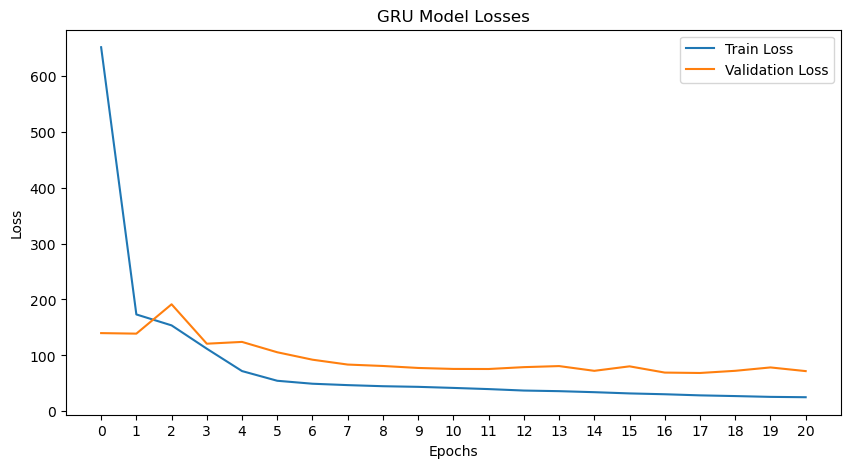

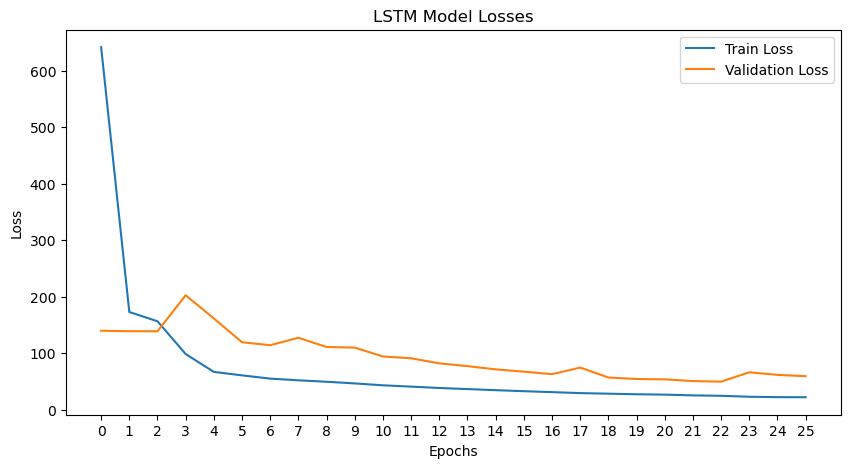

In [59]:
def plot_losses(train_losses, val_losses, title):
    plt.figure(figsize=(10, 5))
    plt.plot(train_losses, label='Train Loss')
    plt.plot(val_losses, label='Validation Loss')
    plt.title(title)
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.xticks(np.arange(0, len(train_losses), step=1))
    plt.show()
plot_losses(train_losses_gru, val_losses_gru, 'GRU Model Losses')
plot_losses(train_losses_lstm, val_losses_lstm, 'LSTM Model Losses')

In [58]:
def calculate_additional_metrics(model, test_loader, device):
    model.eval()
    predictions = []
    actuals = []
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            predictions.extend(output.view(-1).cpu().numpy())
            actuals.extend(target.view(-1).cpu().numpy())    
    r2 = r2_score(actuals, predictions)
    mae = mean_absolute_error(actuals, predictions)
    explained_variance = explained_variance_score(actuals, predictions)
    mse = mean_squared_error(actuals, predictions)    
    return mse, r2, mae, explained_variance
mse_lstm, r2_lstm, mae_lstm, explained_variance_lstm = calculate_additional_metrics(lstm_model, test_loader_seq, device)
print(f'LSTM Model MSE: {mse_lstm:.4f}')
print(f'LSTM Model R2 Score: {r2_lstm:.4f}')
print(f'LSTM Model MAE: {mae_lstm:.4f}')
print(f'LSTM Model Explained Variance: {explained_variance_lstm:.4f}')
mse_gru, r2_gru, mae_gru, explained_variance_gru = calculate_additional_metrics(gru_model, test_loader_seq, device)
print(f'GRU Model MSE: {mse_gru:.4f}')
print(f'GRU Model R2 Score: {r2_gru:.4f}')
print(f'GRU Model MAE: {mae_gru:.4f}')
print(f'GRU Model Explained Variance: {explained_variance_gru:.4f}')

LSTM Model MSE: 41.5762
LSTM Model R2 Score: 0.4380
LSTM Model MAE: 5.2143
LSTM Model Explained Variance: 0.4842
GRU Model MSE: 62.3136
GRU Model R2 Score: 0.1576
GRU Model MAE: 6.5497
GRU Model Explained Variance: 0.6066


Zunächst sollen die beiden abgebildeten Diagramme "GRU Model Losses" und "LSTM Model Losses" analysiert und interpretiert werden. Das Diagramm "GRU Model Losses" zeigt den Train- und Validation-Loss während des Trainingsprozesses des GRU-Modells in Abhängigkeit von der Anzahl der Epochen. Es ist zu erkennen, dass der Train- als auch der Validation-Loss zu Beginn des Trainings zunächst sehr stark abnehmen, die Kurve des Train-Loss jedoch bereits ungefähr ab der 4. Epoche stark abflacht, was wiederum auf einen schnellen Lernprozess des Modells hindeutet. Auffallend ist hier, dass der Graph des Validation-Loss den Graph des Train-Loss "kreuzt" und dann konstant größer als dieser ist. Dies könnte auf Overfitting des Modells hinweisen. Das Diagramm "LSTM Model Losses" zeigt ebenfalls den Train- und Validation-Loss während des Trainingsprozesses in Abhängigkeit von der Anzahl der Epochen, wobei hier jedoch der Trainingsprozess des LSTM-Modells dargestellt wird. Ähnlich wie beim GRU-Modell ist zu Beginn des Trainings ein ähnlich starker Abfall des Train- und Validation-Loss zu erkennen, was ebenfalls auf eine gute Generalisierung des Modells hinweist. Allerdings zeigt das LSTM-Modell über mehr Epochen hinweg einen langsameren Abfall des Verlustes im Vergleich zum GRU-Modell. Dies könnte auf eine langsamere Lerngeschwindigkeit oder auf eine höhere Komplexität des Modells hinweisen, die mehr Zeit benötigt, um zu konvergieren. Diese, im Vergleich zum GRU-Modell höhere Komplexität trifft, wie bereits oben beschrieben, auf das LSTM-Modell zu. Das LSTM-Modell benötigt, verglichen mit dem GRU-Modell, gleichfalls  mehr Epochen zum trainieren. Das LSTM-Modell hingegen zeigt stärkere Anzeichen von Overfitting, was durch eben diese höhere Komplexität zu erklären sein könnte.
Anschließend werden die angegebenen Metriken des Modells miteinander verglichen und interpretiert. Der MSE des GRU-Modells beträgt 62.3136 und der MSE des LSTM-Modells beträgt 41.5762, womit das LSTM-Modell besser abschneidet und somit im Durchschnitt genauere Vorhersagen trifft. Der MAE des GRU-Modells liegt bei 6.5497 und der MAE des LSTM-Modells liegt bei 5.2143. Daraus lässt sich schließen, dass die Vorhersagen des LSTM-Modells im Durchschnitt näher an den tatsächlichen Werten liegen. Das GRU-Modell hat eine Model Explained Variance von 0.6066, wohingegen der MAE-Wert des LSTM-Modell bei 0.4842 liegt. Das bedeutet, dass das GRU-Modell die Varianz in den Daten etwas besser erfasst, was darauf hindeuten könnte, dass es besser auf die Daten reagiert, aber, die weiteren Metriken miteinbeziehend, die Genauigkeit der Vorhersage dennoch schlechter als beim LSTM-Modell ist. Der R2-Score des GRU-Modells besitzt einen Wert von 0.1576, was im Gegensatz zum R2-Score des LSTM-Modells von 0.4380 deutlich geringer ist. Dies bedeutet, dass das LSTM-Modell im Vergleich zum GRU-Modell eine bessere Leistung in Bezug auf die Erklärung der Varianz der Zielvariablen aufweist, was letztendlich zu einer höheren Prognosegenauigkeit führt.

# 6. Reflexion & Fazit

Wie bereits beschrieben das LSTM-Modell  zeigt im Vergleich eine bessere Passgenauigkeit mit niedrigeren Fehlern (MSE und MAE) und einem höheren R2-Score, was auf eine genauere Vorhersagefähigkeit hinweist. Allerdings deutet der Verlauf des Validation-Loss darauf hin, dass das Modell anfällig für Overfitting sein könnte, was unter anderem wiederum mit der höheren Komplexität des Modells erklärt werden könnte. Um das Risiko des Overfittings zu mininmieren können verschiedene Maßnahmen angewandt werden. So kann beispielsweise Weight-Decay angewendet werden, um die Komplexität des Modells einzuschränken, indem es die Gewichte während des Trainingsprozess reguliert, um so die Komplexität des Modells zu reduzieren. Ebenso kann mithilfe von Dropout Overfitting reduziert werden, indem während Trainingsprozesses einige der Neuronen deaktiviert werden [11]. Ein weiteres Problem bei der Zeitreihenvorhersage stellen die Trainingsdaten dar, da sie oft verrauscht und chaotisch vorliegen, was wiederum zu Overfitting führen kann. Um dies zu verhindern können unter anderem  Auto-Encoder genutzt werden, um so beispielsweise bestimmte Merkmale aus den Daten zu extrahieren oder verrauschte Daten zu "unterdrücken" [12]. Durch Hinzufügen zusätzlicher Features, wie beispielsweise der Unterscheidung von Wochentagen und Wochenenden kann der Trainingsprozess ebenfalls optimiert werden.
Zusammenfassend ist festzuhalten, dass, wie bereits beschrieben, noch viel Potenzial zur Optimierung besteht. Zukünftige Arbeiten könnten sich auf die Erkundung neuer Modellarchitekturen, die Integration zusätzlicher Datenquellen und die Anwendung fortgeschrittener Techniken zur Datenvorverarbeitung und -analyse konzentrieren.

# 7. Quellen

[1] Liu, F.; Cai, M.; Wang L. & Lu, Y. (2019): An Ensemble Model Based on Adaptive Noise Reducer and Over-Fitting Prevention LSTM for Multivariate Time Series Forecasting. In: IEEE Access, vol. 7. S. 26102-26115.
[2] Zhang, R.; Li, G. and Ma, Z. (2020): A Deep Learning Based Hybrid Framework for Day-Ahead Electricity Price Forecasting. In: IEEE Access, vol. 8. S. 143423-143436.
[3] Zema, T. & Sulich, A. (2022): Models of Electricity Price Forecasting: Bibliometric Research. In: Energies 15, no. 15.
[4] https://www.kaggle.com/datasets/nicholasjhana/energy-consumption-generation-prices-and-weather/data
[5] Shiri, F.; Perumal, T.; Mustapha, N. & Mohamed, R. (2023): A Comprehensive Overview and Comparative Analysis on Deep Learning Models: CNN, RNN, LSTM, GRU.
[6] James, G. et al. (2021): An Introduction to Statistical Learning: With Applications in R. New York: Springer.
[7] Pethe. H. & Riemann, J. (2003): Zur Relevanz der Extremwerte meteorologischer Größen. In: Chmielewski & Foken (Hrsg.): Beiträge zur Klima- und Meeresforschung. Berlin und Bayreuth. S. 33-38.
[8] Hersbach, H., Bell, B., Berrisford, P., Biavati, G., Horányi, A., Muñoz Sabater, J., Nicolas, J., Peubey, C., Radu, R., Rozum, I., Schepers, D., Simmons, A., Soci, C., Dee, D. & Thépaut, J-N. (2023): ERA5 monthly averaged data on single levels from 1940 to present. Copernicus Climate Change Service (C3S) Climate Data Store (CDS), DOI: 10.24381/cds.f17050d7 (letzter Zugriff: 25.01.2024)
[9] City Population (2021). Spanien: Die zehn größten Städte im Jahr 2021 (nach Einwohnerzahl). Statista. Statista GmbH. Zugriff: 01. Februar 2024. https://de.statista.com/statistik/daten/studie/200622/umfrage/groesste-staedte-in-spanien/
[10] Shumway, R. & Stoffer, D. (2017): Time Series Analysis and Its Applications.
[11] Ookura, S. & Mori, H. (2020): An Efficient Method for Wind Power Generation Forecasting by LSTM in Consideration of Overfitting Prevention. In: IFAC-PapersOnLine, Volume 53, Issue 2, S. 12169-12174.
[12] Liu, F.; Cai, M.; Wang, L. & Lu, Y. (2019): An Ensemble Model Based on Adaptive Noise Reducer and Over-Fitting Prevention LSTM for Multivariate Time Series Forecasting. In IEEE Access, vol. 7. S. 26102-26115.